# 03 · Aprendizaje supervisado

En este notebook entrenamos y evaluamos los modelos que estiman si una reserva se va a cancelar. Empezamos por una regresión logística, que nos sirve de modelo base y nos deja leer qué variables pesan.

## 1. Qué vamos a predecir y con qué datos

### 1.1 El problema

El componente supervisado responde las dos primeras preguntas del notebook 01: qué características de una reserva permiten anticipar una cancelación y qué tan bien se puede predecir con lo que se sabe al momento de reservar. La idea es que, cuando entra una reserva, el modelo le asigne un riesgo de cancelación y el hotel decida qué hacer con ella: confirmarla con el cliente unos días antes, pedirle un depósito o contarla dentro de la sobreventa.

Es un problema de clasificación binaria. La variable objetivo es `is_canceled`, que vale 1 si la reserva se canceló.

### 1.2 Los datos

Usamos lo que dejó el notebook 02 en `data/processed/`. Resumido:

- Se quitaron las filas imposibles (tarifas fuera de rango, reservas sin huéspedes o sin noches) y los duplicados sobre las columnas que ve el modelo. Las reservas con exactamente las mismas entradas quedan en un mismo `grupo_perfil`.
- Solo entran variables que se conocen al hacer la reserva: las numéricas y categóricas de `src/preprocesamiento.py`. Además de las siete que la sección 3.8 del notebook 01 recomendó dejar por fuera, el notebook 02 sacó `deposit_type`, `adr` y `total_of_special_requests`, porque en este CSV pueden reflejar pagos, tarifas o pedidos que se registran después de la reserva.
- La base quedó partida en entrenamiento (80 %) y prueba (20 %), sin perfiles compartidos. **La prueba no la cargamos en estas secciones**: se usa una sola vez, en la sección 4, cuando ya estén escogidos el modelo y el umbral.
- El escalado de las numéricas y el one-hot de las categóricas están en `crear_preprocesador()`, que va dentro del `Pipeline` de cada modelo. Así, en cada partición de la validación cruzada esas transformaciones se ajustan solo con las filas de ajuste.

Por esa limpieza, la tasa de cancelación que ve el modelo es menor que la del CSV original (37,0 %): buena parte de las filas repetidas eran reservas canceladas.

### 1.3 Cómo evaluamos

- **Validación cruzada de 5 particiones, solo con entrenamiento**, usando `crear_particionador()`: estratificada por `is_canceled` y agrupada por `grupo_perfil`, para que dos reservas con las mismas entradas no queden una en ajuste y la otra en validación. Calculamos las particiones una sola vez y todos los modelos usan las mismas, así la comparación es justa.
- **Métricas del enunciado:** F1, Recall, Precision y ROC-AUC. Como apoyo, el PR-AUC (precisión promedio), que se fija solo en qué tan bien se encuentran las canceladas; su valor de referencia es la tasa de cancelación y no 0,5 como en el ROC-AUC.
- Reportamos la media y la desviación entre particiones, y también la media en entrenamiento, para ver si hay sobreajuste.
- **Punto de referencia:** un clasificador que marca todas las reservas como canceladas. Un modelo que no le gane a eso no sirve.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path("../src").resolve()))

from preprocesamiento import (
    COLUMNAS_CATEGORICAS,
    COLUMNAS_NUMERICAS,
    COLUMNAS_PREDICTORAS,
    GRUPO,
    OBJETIVO,
    SEMILLA,
    crear_particionador,
    crear_preprocesador,
)

RUTA_ENTRENAMIENTO = Path("../data/processed/entrenamiento.csv.gz")
METRICAS = {
    "f1": "F1",
    "recall": "Recall",
    "precision": "Precision",
    "roc_auc": "ROC-AUC",
    "average_precision": "PR-AUC",
}
MAX_ITERACIONES = 1_000
DECILES = 10
ASOCIACION_ALTA = 0.5
N_COEFICIENTES = 20
DIAS_ANTICIPACION = 30

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"

sns.set_theme(style="whitegrid")

In [2]:
entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
X_entrenamiento = entrenamiento[list(COLUMNAS_PREDICTORAS)]
y_entrenamiento = entrenamiento[OBJETIVO]
grupos_entrenamiento = entrenamiento[GRUPO]

print(f"Entrenamiento: {len(entrenamiento):,} reservas en {grupos_entrenamiento.nunique():,} perfiles")
print(f"Predictoras: {len(COLUMNAS_NUMERICAS)} numéricas y {len(COLUMNAS_CATEGORICAS)} categóricas")
print(f"Cancelación: {y_entrenamiento.mean():.1%}")

Entrenamiento: 63,351 reservas en 58,552 perfiles
Predictoras: 10 numéricas y 8 categóricas
Cancelación: 29.2%


Calculamos las cinco particiones y dejamos dos funciones: `validar_modelo` corre la validación cruzada de un modelo y devuelve sus métricas, y `tabla_validacion` las muestra como media ± desviación. Las usan todos los modelos de este notebook.

In [3]:
particiones = list(crear_particionador().split(X_entrenamiento, y_entrenamiento, grupos_entrenamiento))


def validar_modelo(nombre, modelo):
    """Corre la validación cruzada en las particiones fijas y devuelve una fila por métrica."""
    puntajes = cross_validate(modelo, X_entrenamiento, y_entrenamiento, cv=particiones,
                              scoring=list(METRICAS), return_train_score=True)
    return pd.DataFrame([
        {
            "modelo": nombre,
            "métrica": etiqueta,
            "media": puntajes[f"test_{clave}"].mean(),
            "desviación": puntajes[f"test_{clave}"].std(),
            "media en entrenamiento": puntajes[f"train_{clave}"].mean(),
        }
        for clave, etiqueta in METRICAS.items()
    ])


def tabla_validacion(resultados):
    """Una fila por modelo y una columna por métrica, con media ± desviación en validación."""
    valores = resultados.assign(
        valor=resultados["media"].map("{:.3f}".format) + " ± " + resultados["desviación"].map("{:.3f}".format)
    )
    tabla = valores.pivot(index="modelo", columns="métrica", values="valor")
    return tabla.loc[resultados["modelo"].unique(), list(METRICAS.values())]


resumen_particiones = pd.DataFrame([
    {
        "partición": numero,
        "filas de ajuste": len(ajuste),
        "filas de validación": len(validacion),
        "cancelación en validación (%)": y_entrenamiento.iloc[validacion].mean() * 100,
    }
    for numero, (ajuste, validacion) in enumerate(particiones, start=1)
]).set_index("partición")
resumen_particiones.round(2)

,filas de ajuste,filas de validación,cancelación en validación (%)
partición,,,
1,50680,12671,29.22
2,50681,12670,29.22
3,50680,12671,29.22
4,50682,12669,29.22
5,50681,12670,29.22


Las cinco particiones tienen tamaños y tasas de cancelación casi iguales, así que las diferencias entre particiones que veamos después vienen del modelo y no de que una partición haya quedado rara.

## 2. Regresión logística

### 2.1 Por qué empezamos por aquí

La regresión logística estima la probabilidad de cancelación a partir de una suma ponderada de las variables. Esa suma está en la escala del logit, que es el logaritmo de los odds (la probabilidad de cancelar dividida entre la de no cancelar), y la función logística la convierte en un número entre 0 y 1.

La escogimos como primer modelo por cuatro razones:

- **Es el modelo base natural para clasificación binaria.** Si un modelo más complejo no le gana, no vale la pena la complejidad.
- **Se puede interpretar.** Cada coeficiente dice si una variable sube o baja el riesgo y cuánto, que es justo lo que pide la primera pregunta.
- **Es rápida de entrenar**, incluso con las columnas que salen del one-hot.
- **Da probabilidades** y no solo un sí o un no, así que el hotel puede ordenar las reservas de más a menos riesgo.

Sus supuestos:

- **Relación lineal entre cada variable numérica y el logit.** Si el riesgo sube rápido y después se aplana, una sola pendiente no lo describe.
- **Observaciones independientes.** Los duplicados la rompían; el notebook 02 los quitó y la validación agrupada evita que perfiles iguales queden a los dos lados.
- **Poca multicolinealidad.** Si dos variables dicen casi lo mismo, el modelo puede repartir el efecto entre ellas de cualquier manera y los coeficientes ya no se pueden leer uno por uno.

No supone normalidad ni varianzas iguales, como la regresión lineal.

Sus limitaciones: no capta interacciones (por ejemplo, que la anticipación pese distinto en cada hotel) ni relaciones no lineales, a menos que las construyamos a mano; depende de la escala de las variables, y por eso el preprocesador estandariza las numéricas; y en categorías con pocas filas puede dar coeficientes grandes que no significan mucho.

Usamos la regularización que trae por defecto scikit-learn: L2 (`l1_ratio=0`) con `C=1`. La L2 encoge los coeficientes y ayuda cuando hay variables redundantes. El valor de `C` se ajusta en la sección 4.

### 2.2 ¿Se cumplen los supuestos?

Revisamos con datos de entrenamiento los dos supuestos que se pueden medir. Para la relación lineal partimos cada variable numérica con muchos valores en deciles y calculamos el logit observado de la cancelación en cada uno: si el supuesto se cumple, los puntos deberían quedar más o menos sobre una recta.

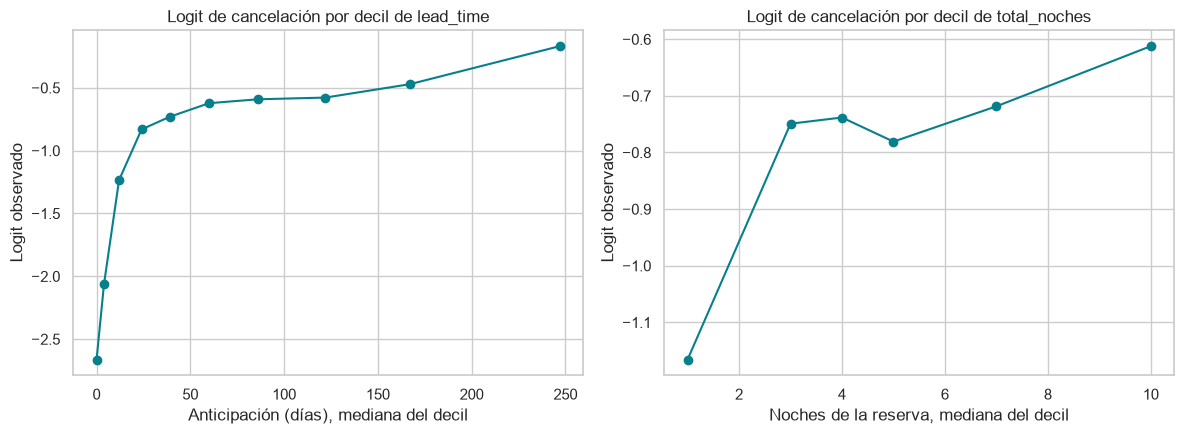

lead_time


,0,1,2,3,4,5,6,7,8,9
mediana,0.00,4.00,12.00,24.00,39.00,60.00,86.00,122.00,167.00,247.00
cancelación (%),6.52,11.32,22.55,30.35,32.51,34.93,35.64,35.95,38.43,45.80
logit,-2.66,-2.06,-1.23,-0.83,-0.73,-0.62,-0.59,-0.58,-0.47,-0.17


total_noches


,0,1,2,3,4,5
mediana,1.00,3.00,4.00,5.00,7.00,10.00
cancelación (%),23.76,32.10,32.34,31.41,32.77,35.16
logit,-1.17,-0.75,-0.74,-0.78,-0.72,-0.61


In [4]:
def logit_por_decil(variable):
    """Logit observado de la cancelación en cada decil de una variable numérica."""
    deciles = pd.qcut(X_entrenamiento[variable], q=DECILES, duplicates="drop")
    tasa = y_entrenamiento.groupby(deciles, observed=True).mean()
    return pd.DataFrame({
        "mediana": X_entrenamiento[variable].groupby(deciles, observed=True).median().values,
        "cancelación (%)": tasa.values * 100,
        "logit": np.log(tasa / (1 - tasa)).values,
    })


variables_continuas = {"lead_time": "Anticipación (días)", "total_noches": "Noches de la reserva"}
logits = {variable: logit_por_decil(variable) for variable in variables_continuas}

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (variable, etiqueta) in zip(ejes, variables_continuas.items()):
    ax.plot(logits[variable]["mediana"], logits[variable]["logit"], marker="o", color=COLOR_PRINCIPAL)
    ax.set_title(f"Logit de cancelación por decil de {variable}")
    ax.set_xlabel(f"{etiqueta}, mediana del decil")
    ax.set_ylabel("Logit observado")
plt.tight_layout()
plt.show()

for variable in variables_continuas:
    print(variable)
    display(logits[variable].round(2).T)

**¿Qué vemos?**

- `lead_time` no cumple el supuesto. El logit sube muy rápido en el primer mes, de −2,66 en las reservas para el mismo día o el siguiente (mediana 0 días) a −0,83 con 24 días, y después sube despacio: −0,73 con 39 días y −0,47 con 167. En el último decil (mediana de 247 días) vuelve a subir más fuerte, a −0,17. Una sola pendiente no puede seguir esa curva: queda una pendiente intermedia que se queda corta en las primeras semanas y exagera en el tramo plano.
- En `total_noches` pasa algo parecido: el logit salta entre las reservas de 1 o 2 noches (−1,17) y las de 3 (−0,75), y de ahí en adelante casi no cambia (entre −0,78 y −0,61).

O sea que la logística, con las variables como están, no puede aprovechar del todo la variable que más separaba en el análisis exploratorio. No cambiamos el preprocesador común por eso. Se podría transformar la anticipación (con su logaritmo o por tramos), pero preferimos dejarlo como una limitación medida del modelo lineal. El bosque aleatorio de la sección 3 no necesita este supuesto.

Ahora la multicolinealidad. En las numéricas usamos el factor de inflación de la varianza (VIF): para cada variable ajustamos una regresión lineal con las demás y calculamos 1 / (1 − R²). Un VIF cercano a 1 dice que la variable aporta información propia, y por encima de 5 o 10 se considera problemático. Las categóricas no tienen VIF, así que medimos la asociación entre cada par con la V de Cramér, la misma que usamos en el Evento 3 (no está en las guías del curso): va de 0, ninguna relación, a 1, cuando una determina a la otra.

In [5]:
def factores_inflacion_varianza(datos):
    """VIF de cada columna: qué tanto la explican las demás con una regresión lineal."""
    factores = {}
    for columna in datos.columns:
        otras = datos.drop(columns=columna)
        r2 = LinearRegression().fit(otras, datos[columna]).score(otras, datos[columna])
        factores[columna] = 1 / (1 - r2)
    return pd.Series(factores, name="VIF").sort_values(ascending=False)


def v_de_cramer(primera, segunda):
    """Asociación entre dos variables categóricas, de 0 a 1."""
    tabla = pd.crosstab(primera, segunda)
    chi2 = chi2_contingency(tabla)[0]
    return np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))


display(factores_inflacion_varianza(X_entrenamiento[list(COLUMNAS_NUMERICAS)]).round(2).to_frame())

asociaciones = pd.DataFrame([
    {"variable 1": primera, "variable 2": segunda,
     "V de Cramér": v_de_cramer(X_entrenamiento[primera], X_entrenamiento[segunda])}
    for posicion, primera in enumerate(COLUMNAS_CATEGORICAS)
    for segunda in COLUMNAS_CATEGORICAS[posicion + 1:]
])
asociaciones.query("`V de Cramér` >= @ASOCIACION_ALTA").sort_values("V de Cramér", ascending=False).round(3)

,VIF
total_noches,2.77
stays_in_weekend_nights,2.62
total_huespedes,1.70
children,1.55
previous_bookings_not_canceled,1.50
is_repeated_guest,1.42
tiene_empresa,1.31
previous_cancellations,1.21
lead_time,1.16
babies,1.03


,variable 1,variable 2,V de Cramér
4,hotel,agent,0.904
18,market_segment,distribution_channel,0.729
22,distribution_channel,agent,0.727
19,market_segment,agent,0.624


**¿Qué vemos?**

- En las numéricas no hay problema. El VIF más alto es el de `total_noches` (2,77), que se explica porque las noches de fin de semana son parte del total, y todos los demás quedan por debajo de 3.
- En las categóricas sí hay mucha redundancia. La agencia casi determina el hotel (0,904): cada agencia trabaja casi siempre con uno de los dos. Segmento, canal y agencia también dicen casi lo mismo entre ellas (entre 0,624 y 0,729), lo que tiene sentido porque una reserva de *Online TA* casi siempre llega por el canal *TA/TO* y por alguna agencia.

Esto no daña la predicción, porque el modelo usa la información venga de donde venga, pero sí la interpretación. El efecto de vender por agencias en línea se puede repartir entre el segmento, el canal y la agencia, y entonces el coeficiente de una sola de esas columnas no es "el efecto" de esa variable. Lo vamos a ver con un caso concreto en la sección 2.4.

### 2.3 El pipeline y los pesos de clase

Armamos un `Pipeline` con el preprocesador del notebook 02 y la logística. La decisión que queda es `class_weight`. Con 29 % de canceladas, la logística sin pesos aprende que lo más común es no cancelar, y con el umbral de 0,5 marca muy pocas reservas como canceladas. Con `class_weight="balanced"`, cada cancelada pesa más en el ajuste, en proporción inversa a qué tan frecuente es su clase, y las dos clases cuentan lo mismo. Para decidir con datos validamos las dos versiones junto con la referencia.

In [6]:
def crear_logistica(pesos_clase=None):
    """Pipeline con el preprocesador del notebook 02 y una regresión logística."""
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", LogisticRegression(class_weight=pesos_clase, max_iter=MAX_ITERACIONES,
                                      random_state=SEMILLA)),
    ])


resultados_validacion = pd.concat([
    validar_modelo("Referencia: todas canceladas", DummyClassifier(strategy="constant", constant=1)),
    validar_modelo("Logística sin pesos", crear_logistica()),
    validar_modelo("Logística con pesos balanceados", crear_logistica("balanced")),
], ignore_index=True)

display(tabla_validacion(resultados_validacion))

sobreajuste = resultados_validacion.query("métrica in ['F1', 'ROC-AUC']").pivot(
    index="modelo", columns="métrica", values=["media en entrenamiento", "media"]
).rename(columns={"media": "media en validación"})
sobreajuste.loc[resultados_validacion["modelo"].unique()].round(3)

métrica,F1,Recall,Precision,ROC-AUC,PR-AUC
modelo,,,,,
Referencia: todas canceladas,0.452 ± 0.000,1.000 ± 0.000,0.292 ± 0.000,0.500 ± 0.000,0.292 ± 0.000
Logística sin pesos,0.369 ± 0.006,0.263 ± 0.005,0.619 ± 0.007,0.751 ± 0.002,0.554 ± 0.005
Logística con pesos balanceados,0.571 ± 0.003,0.764 ± 0.006,0.455 ± 0.002,0.751 ± 0.002,0.553 ± 0.005


media en entrenamiento          \
métrica                                             F1 ROC-AUC   
modelo                                                           
Referencia: todas canceladas                     0.452   0.500   
Logística sin pesos                              0.372   0.754   
Logística con pesos balanceados                  0.573   0.754   

                                media en validación          
métrica                                          F1 ROC-AUC  
modelo                                                       
Referencia: todas canceladas                  0.452   0.500  
Logística sin pesos                           0.369   0.751  
Logística con pesos balanceados               0.571   0.751

**¿Qué vemos?**

- **La referencia** tiene Recall de 1, porque marca todo como cancelado, Precision de 0,292, que es la tasa de cancelación, F1 de 0,452 y ROC-AUC de 0,5, porque no ordena nada.
- **La logística sin pesos** acierta el 61,9 % de las veces que dice "se cancela" (Precision 0,619), pero solo detecta el 26,3 % de las cancelaciones (Recall 0,263). Deja pasar casi tres de cada cuatro. Su F1 (0,369) queda incluso por debajo de la referencia.
- **La logística con pesos balanceados** detecta el 76,4 % de las cancelaciones con una Precision de 0,455, y su F1 sube a 0,571. Le gana a la referencia en F1 y en Precision: de las reservas que marca, cancela el 45,5 %, contra el 29,2 % de marcar todo.
- **El ROC-AUC es el mismo en las dos logísticas (0,751)**, y el PR-AUC casi (0,554 y 0,553). Los pesos no cambian cómo el modelo ordena las reservas de más a menos riesgo; lo que cambian es dónde cae el corte de 0,5. Por eso el F1 de la versión sin pesos se ve tan mal aunque el modelo sí distingue.
- Las desviaciones entre particiones no pasan de 0,007, y la diferencia entre entrenamiento y validación es de milésimas (ROC-AUC de 0,754 contra 0,751). No hay sobreajuste. El límite no está en que el modelo memorice, sino en lo que un modelo lineal puede sacar de estas variables.

**Decisión: `class_weight="balanced"`.** Para el hotel, un modelo que se le escapan tres de cada cuatro cancelaciones no sirve para planear la sobreventa ni para saber a quién llamar. Con pesos balanceados, las dos clases cuentan lo mismo en el ajuste, que es razonable porque, como vimos en el notebook 01, los dos errores le cuestan al hotel. El mismo efecto se podría lograr bajando el umbral del modelo sin pesos; el umbral definitivo se escoge en la sección 4, con validación cruzada.

Este modelo lo ajustamos con todo el entrenamiento para leer sus coeficientes. Antes, una advertencia que sale de usar pesos:

In [7]:
logistica = crear_logistica("balanced").fit(X_entrenamiento, y_entrenamiento)
probabilidad_media = logistica.predict_proba(X_entrenamiento)[:, 1].mean()

print(f"Probabilidad media de cancelar que da el modelo: {probabilidad_media:.1%}")
print(f"Tasa real de cancelación en entrenamiento:      {y_entrenamiento.mean():.1%}")

Probabilidad media de cancelar que da el modelo: 46.1%
Tasa real de cancelación en entrenamiento:      29.2%


Con pesos, las probabilidades quedan infladas: en promedio el modelo le da a cada reserva un riesgo de 46,1 %, cuando la tasa real es de 29,2 %. Para ordenar las reservas o decidir con un umbral eso no importa, pero esos números no se pueden leer como "esta reserva tiene tal probabilidad de cancelarse". Si el hotel los necesitara así, por ejemplo para estimar cuántas habitaciones se van a liberar en una noche, habría que calibrarlos.

### 2.4 Qué dicen los coeficientes

Cómo leerlos:

- Un coeficiente positivo sube el riesgo de cancelar y uno negativo lo baja. Su exponencial es la **razón de odds**: cuántas veces se multiplican los odds de cancelar.
- Las numéricas están estandarizadas, así que su coeficiente es el cambio por cada desviación estándar de la variable. Para que se entiendan mejor también los pasamos a unidades de la variable.
- El one-hot de este preprocesador no deja una categoría de referencia, así que el coeficiente de una categoría solo se puede comparar con el de otras categorías de la misma variable. Lo que se interpreta es la diferencia entre dos categorías, no el valor solo.
- Todo es una asociación condicionada a las demás variables del modelo, no una causa.

Primero miramos los coeficientes más grandes, sin importar la variable.

Columnas después del one-hot: 163


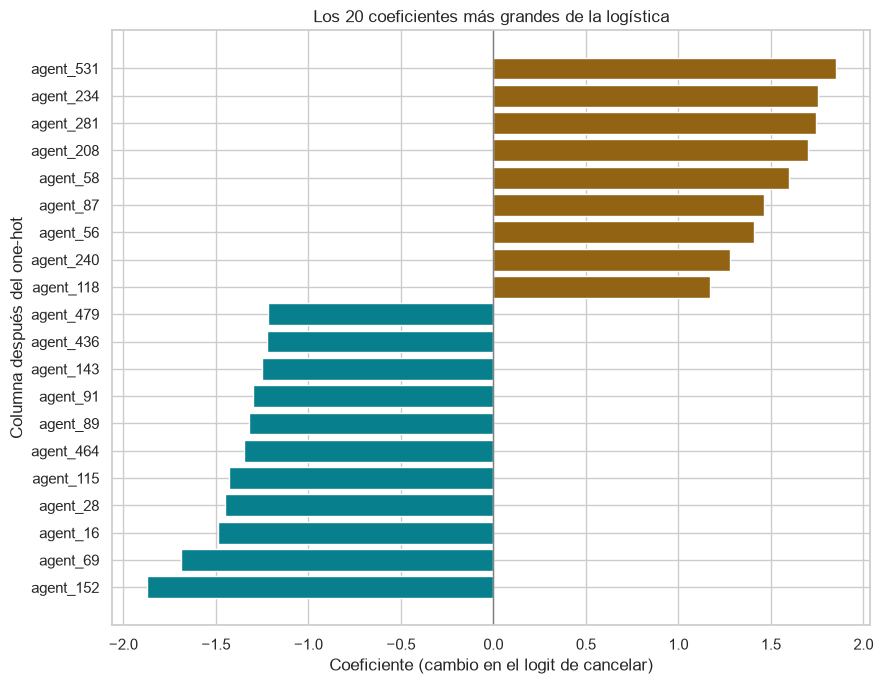

De los 20 coeficientes más grandes, 20 son de agencias
Agencias con columna propia: 108


,reservas,cancelacion,coeficiente
agent,,,
531,48,0.688,1.851
234,21,0.524,1.756
281,23,0.478,1.745
208,29,0.552,1.700
58,38,0.763,1.596
87,23,0.435,1.461
56,30,0.500,1.406
240,9722,0.395,1.277
118,47,0.426,1.169


Las cinco agencias con más reservas:


,reservas,cancelacion,coeficiente
agent,,,
9,21847,0.411,0.716
240,9722,0.395,1.277
Sin agente,8272,0.140,0.161
14,2572,0.179,-0.124
7,2504,0.133,-0.833


In [8]:
preprocesador = logistica.named_steps["preprocesamiento"]
coeficientes = pd.Series(
    logistica.named_steps["modelo"].coef_[0],
    index=preprocesador.get_feature_names_out(),
)
coeficientes.index = (
    coeficientes.index.str.replace(r"^(numericas|categoricas)__", "", regex=True)
    .str.replace("infrequent_sklearn", "poco frecuentes")
)
print(f"Columnas después del one-hot: {len(coeficientes)}")

mayores = coeficientes.loc[coeficientes.abs().nlargest(N_COEFICIENTES).index].sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(mayores.index, mayores.values,
        color=np.where(mayores > 0, COLOR_RIESGO, COLOR_PRINCIPAL))
ax.axvline(0, color="gray", linewidth=1)
ax.set_title(f"Los {N_COEFICIENTES} coeficientes más grandes de la logística")
ax.set_xlabel("Coeficiente (cambio en el logit de cancelar)")
ax.set_ylabel("Columna después del one-hot")
plt.tight_layout()
plt.show()

agencias_mayores = [
    nombre.removeprefix("agent_") for nombre in mayores.index
    if nombre.startswith("agent_") and nombre != "agent_poco frecuentes"
]
por_agencia = entrenamiento.groupby("agent")[OBJETIVO].agg(reservas="size", cancelacion="mean")
por_agencia["coeficiente"] = coeficientes.reindex("agent_" + por_agencia.index).to_numpy()
columnas_agencia = coeficientes.index.str.startswith("agent_") & (coeficientes.index != "agent_poco frecuentes")

print(f"De los {N_COEFICIENTES} coeficientes más grandes, {len(agencias_mayores)} son de agencias")
print(f"Agencias con columna propia: {columnas_agencia.sum()}")
display(por_agencia.loc[agencias_mayores].sort_values("coeficiente", ascending=False).round(3))
print("Las cinco agencias con más reservas:")
por_agencia.nlargest(5, "reservas").round(3)

**¿Qué vemos?**

- **La agencia es la señal más fuerte del modelo**: los 20 coeficientes más grandes son de agencias (108 tienen columna propia). Los cinco positivos más grandes son de agencias pequeñas, de 21 a 48 reservas, que cancelan entre el 47,8 % y el 76,3 %. Entre los negativos hay agencias como la 28, con 1.122 reservas y apenas 6,2 % de cancelación.
- Las dos agencias más grandes, la 9 y la 240, concentran casi la mitad del entrenamiento, cancelan alrededor del 40 % y tienen coeficientes positivos (0,716 y 1,277). Las reservas sin agencia cancelan 14,0 %.
- Lo más probable es que la agencia esté resumiendo cosas que el dataset no trae, como las condiciones de cancelación que ofrece cada una o si reserva bloques de habitaciones para revender. Eso le sirve al modelo para predecir, pero tiene dos problemas. Los códigos están anonimizados, así que el hotel sabría qué agencia es cada una y nosotros no. Y los coeficientes de agencias con 20 o 30 reservas se apoyan en muy pocos datos y pueden cambiar bastante con otra muestra; eso se revisa en la sección de estabilidad.

Ahora las variables numéricas, con la razón de odds por desviación estándar y por unidad.

In [9]:
escalador = preprocesador.named_transformers_["numericas"]
numericas = pd.DataFrame({
    "coeficiente": coeficientes[list(COLUMNAS_NUMERICAS)].to_numpy(),
    "desviación estándar": escalador.scale_,
}, index=list(COLUMNAS_NUMERICAS))
numericas["razón de odds por desviación"] = np.exp(numericas["coeficiente"])
numericas["razón de odds por unidad"] = np.exp(numericas["coeficiente"] / numericas["desviación estándar"])
display(numericas.sort_values("coeficiente", ascending=False).round(3))

coeficiente_por_dia = numericas.loc["lead_time", "coeficiente"] / numericas.loc["lead_time", "desviación estándar"]
print(f"Por cada {DIAS_ANTICIPACION} días más de anticipación, los odds de cancelar se multiplican por "
      f"{np.exp(coeficiente_por_dia * DIAS_ANTICIPACION):.2f}")

,coeficiente,desviación estándar,razón de odds por desviación,razón de odds por unidad
previous_cancellations,0.750,0.378,2.116,7.250
lead_time,0.404,82.869,1.498,1.005
total_noches,0.172,2.776,1.188,1.064
total_huespedes,0.039,0.826,1.040,1.048
children,0.028,0.473,1.028,1.060
stays_in_weekend_nights,-0.035,1.037,0.966,0.967
babies,-0.061,0.106,0.940,0.561
tiene_empresa,-0.111,0.226,0.895,0.613
is_repeated_guest,-0.190,0.194,0.827,0.375
previous_bookings_not_canceled,-0.550,1.822,0.577,0.740


Por cada 30 días más de anticipación, los odds de cancelar se multiplican por 1.16


**¿Qué vemos?**

- **Las cancelaciones previas son la numérica que más pesa.** Por cada cancelación anterior del cliente, los odds de que cancele esta reserva se multiplican por 7,25, con las demás variables iguales. Al revés, cada reserva anterior que el cliente sí cumplió los multiplica por 0,74. El historial dice mucho, aunque muy pocos clientes lo tienen: casi todos están en cero, y por eso la desviación de las cancelaciones previas es de apenas 0,378.
- **La anticipación sube el riesgo**: por cada 30 días más, los odds se multiplican por 1,16. Va en la misma dirección que el análisis exploratorio, pero como vimos en la 2.2, la logística le pone una sola pendiente a una relación que en realidad sube rápido al principio y después se aplana.
- Ser cliente repetido multiplica los odds por 0,38 y que la reserva tenga una empresa detrás, por 0,61: los dos bajan el riesgo. Las noches suman un poco (1,06 por noche) y la composición de los huéspedes queda cerca de 1 (1,05 por huésped y 1,06 por niño). Los bebés dan 0,56, pero son tan pocos (desviación de 0,106) que no le daríamos mucho peso a ese número.

Por último, cuatro de las categóricas, comparando cada coeficiente con la cancelación que se observa en esa categoría.

In [10]:
def coeficientes_de(variable):
    """Coeficiente de cada categoría junto con su número de reservas y su cancelación observada."""
    prefijo = f"{variable}_"
    propios = coeficientes[coeficientes.index.str.startswith(prefijo)]
    observado = entrenamiento.groupby(variable)[OBJETIVO].agg(reservas="size", cancelacion="mean")
    return (
        pd.DataFrame({"categoría": propios.index.str.removeprefix(prefijo), "coeficiente": propios.to_numpy()})
        .join(observado, on="categoría", how="inner")
        .assign(variable=variable)
        .set_index(["variable", "categoría"])
        .sort_values("coeficiente", ascending=False)
    )


categoricas_principales = ["hotel", "customer_type", "market_segment", "distribution_channel"]
comparacion = pd.concat([coeficientes_de(variable) for variable in categoricas_principales])
display(comparacion.round(3))

diferencia_hotel = coeficientes["hotel_City Hotel"] - coeficientes["hotel_Resort Hotel"]
print(f"City Hotel frente a Resort Hotel: razón de odds de {np.exp(diferencia_hotel):.2f}")

coeficiente  reservas  cancelacion
variable             categoría                                          
hotel                City Hotel             0.299     38854        0.318
                     Resort Hotel          -0.390     24497        0.252
customer_type        Transient              0.569     54573        0.309
                     Group                 -0.023       421        0.114
                     Contract              -0.178      2298        0.172
                     Transient-Party       -0.459      6059        0.200
market_segment       Groups                 0.770      2330        0.394
                     Corporate              0.151      2925        0.130
                     Aviation               0.099       154        0.214
                     Online TA             -0.328     39017        0.364
                     Offline TA/TO         -0.342      9599        0.163
                     Complementary         -0.450       502        0.120
                     Direct                -0.511      8822        0.155
distribution_channel Corporate             -0.084      3358        0.144
                     GDS                   -0.292       134        0.194
                     TA/TO                 -0.318     50396        0.328
                     Direct                -0.399      9458        0.158

City Hotel frente a Resort Hotel: razón de odds de 1.99


**¿Qué vemos?**

- **Hotel.** Con las demás variables iguales, una reserva del City Hotel tiene 1,99 veces los odds de cancelar de una del Resort Hotel. Va en la misma dirección que la tasa observada (31,8 % contra 25,2 %).
- **Tipo de cliente.** *Transient*, la reserva suelta, es el que más sube el riesgo, y *Transient-Party*, la reserva suelta ligada a otra, el que más lo baja. También coincide con las tasas observadas (30,9 % contra 20,0 %).
- **Segmento y canal: aquí se ve la redundancia de la 2.2.** *Online TA* es el segmento que más cancela (36,4 %), pero su coeficiente queda por debajo del de *Corporate*, que solo cancela el 13,0 %. No es una contradicción: las agencias y el canal ya se llevaron buena parte de lo que explica vender en línea, y al segmento le queda lo poco que no explican ellas. Por eso no decimos "el segmento *Online TA* baja el riesgo": lo que se puede decir es que, entre reservas de la misma agencia y el mismo canal, el segmento agrega poco.
- *Groups* tiene el coeficiente más alto de los segmentos (0,770), con 39,4 % de cancelación observada. En el notebook 01 vimos que la tasa de *Groups* cambiaba mucho al quitar duplicados, así que este resultado no lo daríamos por firme.

Lo que estos coeficientes no permiten concluir: son asociaciones dentro de este modelo, no causas. Que una agencia tenga un coeficiente alto no quiere decir que cambiar de agencia vaya a bajar las cancelaciones; quiere decir que, con lo demás igual, sus reservas se cancelan más.

### 2.5 Cierre de la logística

- Con pesos balanceados, la logística obtiene en validación cruzada un F1 de 0,571, Recall de 0,764, Precision de 0,455 y ROC-AUC de 0,751, con desviaciones muy pequeñas entre particiones y sin sobreajuste. Le gana con claridad a marcar todo como cancelado.
- Es un desempeño moderado. Vemos dos razones, y las dos se midieron arriba: las variables que se conocen al reservar son pocas (dejamos por fuera el depósito, el país y los pedidos especiales), y el modelo es lineal, mientras que la anticipación y las noches no lo son.
- Lo que más anticipa una cancelación, según este modelo, es la agencia, el historial del cliente (cancelaciones previas y reservas cumplidas), el hotel, el tipo de cliente y la anticipación.

La sección 3 entrena un bosque aleatorio con las mismas variables y las mismas particiones, para ver si un modelo que capta relaciones no lineales e interacciones le gana a la logística. `validar_modelo`, `tabla_validacion` y `resultados_validacion` quedan listos para agregarle sus resultados.

## 3. Máquina de vectores de soporte (SVM)

### 3.1 Por qué una SVM

En el plan inicial el segundo modelo era un bosque aleatorio. Lo cambiamos por una máquina de vectores de soporte porque la guía de las semanas 12-13 trabaja como modelos supervisados la regresión lineal, la regresión logística, KNN y SVM. Entre KNN y SVM escogimos la SVM: KNN tiene que guardar todo el entrenamiento y medir distancias contra él en cada predicción, y con tantas columnas de one-hot esas distancias dependen sobre todo de si dos reservas comparten agencia o segmento. La SVM, en cambio, resume el entrenamiento en una frontera de decisión regularizada.

Cómo funciona: la SVM busca la frontera que separa las reservas canceladas de las no canceladas dejando el mayor margen posible entre las dos clases. Las reservas que quedan sobre el margen o del lado equivocado son los **vectores de soporte**, y son las únicas que definen la frontera; las demás no cambian nada. Como las dos clases casi nunca se pueden separar del todo, usamos margen suave: el parámetro `C` dice cuánto castiga el modelo cada reserva mal ubicada. Con `C` grande intenta acertarlas todas y puede sobreajustar; con `C` pequeño acepta más errores a cambio de una frontera más simple.

Con el kernel lineal la frontera es un hiperplano, como en la logística. Nosotros usamos el **kernel RBF** (de base radial), que mide qué tan parecidas son dos reservas según la distancia entre ellas. Con ese kernel la frontera sigue siendo un hiperplano, pero en un espacio de más dimensiones que el modelo nunca construye; vista en las variables originales, la frontera es curva. El parámetro `gamma` controla qué tan rápido se pierde el parecido con la distancia, o sea, qué tan curva puede ser la frontera.

La escogimos como segundo modelo porque ataca lo que la logística no pudo hacer en la sección 2:

- **Relaciones no lineales.** En la 2.2 vimos que el riesgo sube muy rápido en el primer mes de anticipación y después se aplana, y que las noches pasan de 1 o 2 a 3 y de ahí casi no cambian. Con el kernel RBF la frontera se puede doblar para seguir esas curvas sin que nosotros transformemos las variables.
- **Interacciones.** El parecido entre dos reservas se mide con todas las variables a la vez, así que la frontera puede depender de combinaciones, por ejemplo de la anticipación en un hotel o en el otro, sin construir esas columnas a mano.
- **Funciona bien con muchas columnas.** Después del one-hot el modelo ve más de 150 columnas, y la SVM está pensada para encontrar el margen en espacios de muchas dimensiones.
- **Tiene una regularización explícita.** Maximizar el margen con `C` limita la complejidad de la frontera, y eso la protege del sobreajuste.

Sus supuestos:

- **Las variables tienen que estar en escalas comparables.** El kernel RBF se basa en distancias, así que una variable con valores grandes dominaría a las demás. La guía de la semana 5 lo plantea para k-NN y aplica igual aquí. El `crear_preprocesador()` del notebook 02 ya estandariza las numéricas, y el one-hot deja las categóricas en 0 y 1, un rango parecido.
- **Reservas independientes y parecidas a las futuras.** Por eso la validación sigue agrupada por `grupo_perfil`, y por eso todo lo que concluyamos vale para reservas como las de 2015 a 2017.

No supone una forma para la relación entre las variables y la cancelación, ni normalidad.

Sus limitaciones frente a estos datos:

- **Es lenta con muchas filas.** El costo de entrenar crece más rápido que el número de reservas, y para predecir hay que comparar cada reserva nueva con todos los vectores de soporte. Con unas 50.000 reservas por partición, la validación cruzada tarda varios minutos, y eso limita cuántas combinaciones de hiperparámetros se pueden probar en la sección 4.
- **No se puede interpretar como la logística.** Con el kernel RBF no hay un coeficiente por variable. Qué variables pesan se tiene que medir aparte, y eso queda para la sección 5.
- **No da probabilidades.** Entrega un puntaje: la distancia con signo a la frontera. Para el ROC-AUC y el PR-AUC basta, porque esas métricas solo necesitan ordenar las reservas, y scikit-learn usa ese puntaje. Si el hotel necesitara probabilidades, habría que calibrarlas aparte.

Usamos la configuración por defecto de scikit-learn: `C=1` y `gamma="scale"`, que ajusta `gamma` según el número de columnas y su varianza. Escoger esos valores con validación cruzada es la búsqueda de hiperparámetros de la sección 4; moverlos aquí a ojo sería decidir sin evidencia.

### 3.2 El pipeline y la validación

El `Pipeline` usa el mismo preprocesador que la logística, así que los dos modelos ven exactamente las mismas columnas. Usamos `class_weight="balanced"` por la misma razón que en la 2.3: sin pesos, el modelo tiende a decir que casi nada se cancela, y los dos errores le cuestan al hotel. Además, así comparamos los dos modelos con la misma decisión sobre las clases. Con la SVM no validamos también la versión sin pesos porque cada validación tarda varios minutos, y la 2.3 ya mostró que los pesos mueven el corte y no el orden de las reservas.

Validamos en las mismas cinco particiones y agregamos el resultado a la tabla de la sección 2. Esta celda es la que más tarda del notebook; para que no se demore el triple, `parallel_config(n_jobs=-1)` entrena las cinco particiones al mismo tiempo, una por núcleo del procesador. Eso cambia solo el tiempo, no los resultados.

In [11]:
from joblib import parallel_config
from sklearn.svm import SVC


def crear_svm(pesos_clase=None):
    """Pipeline con el preprocesador del notebook 02 y una SVM con kernel RBF y su configuración por defecto."""
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", SVC(kernel="rbf", class_weight=pesos_clase)),
    ])


with parallel_config(n_jobs=-1):
    resultados_svm = validar_modelo("SVM con pesos balanceados", crear_svm("balanced"))
resultados_validacion = pd.concat([resultados_validacion, resultados_svm], ignore_index=True)

display(tabla_validacion(resultados_validacion))

sobreajuste = resultados_validacion.query("métrica in ['F1', 'ROC-AUC']").pivot(
    index="modelo", columns="métrica", values=["media en entrenamiento", "media"]
).rename(columns={"media": "media en validación"})
sobreajuste.loc[resultados_validacion["modelo"].unique()].round(3)

métrica,F1,Recall,Precision,ROC-AUC,PR-AUC
modelo,,,,,
Referencia: todas canceladas,0.452 ± 0.000,1.000 ± 0.000,0.292 ± 0.000,0.500 ± 0.000,0.292 ± 0.000
Logística sin pesos,0.369 ± 0.006,0.263 ± 0.005,0.619 ± 0.006,0.751 ± 0.002,0.554 ± 0.005
Logística con pesos balanceados,0.571 ± 0.003,0.764 ± 0.006,0.455 ± 0.002,0.751 ± 0.002,0.553 ± 0.005
SVM con pesos balanceados,0.581 ± 0.003,0.746 ± 0.004,0.476 ± 0.004,0.764 ± 0.002,0.572 ± 0.006


media en entrenamiento          \
métrica                                             F1 ROC-AUC   
modelo                                                           
Referencia: todas canceladas                     0.452   0.500   
Logística sin pesos                              0.372   0.754   
Logística con pesos balanceados                  0.574   0.754   
SVM con pesos balanceados                        0.593   0.787   

                                media en validación          
métrica                                          F1 ROC-AUC  
modelo                                                       
Referencia: todas canceladas                  0.452   0.500  
Logística sin pesos                           0.369   0.751  
Logística con pesos balanceados               0.571   0.751  
SVM con pesos balanceados                     0.581   0.764

**¿Qué vemos?**

- **La SVM con pesos balanceados obtiene un F1 de 0,581, Recall de 0,746, Precision de 0,476, ROC-AUC de 0,764 y PR-AUC de 0,572.** Le gana con claridad a marcar todo como cancelado (F1 de 0,452 y ROC-AUC de 0,5) y queda por encima de la logística en casi todo. La comparación detallada está en la 3.4.
- **Hay algo de sobreajuste, pero poco.** En entrenamiento el ROC-AUC es 0,787 y en validación 0,764; el F1 pasa de 0,593 a 0,581. La brecha es más grande que en la logística (0,754 contra 0,751), lo que es de esperar en un modelo con una frontera curva, pero el margen con `C=1` la mantiene pequeña: el modelo no se está aprendiendo las reservas una por una.
- Las desviaciones entre particiones no pasan de 0,006, así que el resultado no depende de cómo quedaron repartidas las reservas.

### 3.3 Cuánto se traslapan las clases

Para entender de dónde sale ese resultado ajustamos la SVM en la primera partición y miramos dos cosas: cuántas reservas de ajuste terminaron como vectores de soporte, y cómo se reparte el puntaje de la SVM en las reservas de validación de esa partición, separando las canceladas de las no canceladas. Usamos la validación de la partición y no todo el entrenamiento para que la gráfica muestre reservas que el modelo no vio. También contamos los perfiles del entrenamiento con reservas canceladas y no canceladas que tienen exactamente las mismas entradas.

In [12]:
PARTICION_DIAGNOSTICO = 0
INTERVALOS_HISTOGRAMA = 60
NOMBRES_CLASE = {0: "No cancelada", 1: "Cancelada"}

ajuste, validacion = particiones[PARTICION_DIAGNOSTICO]
y_ajuste = y_entrenamiento.iloc[ajuste]
svm_particion = crear_svm("balanced").fit(X_entrenamiento.iloc[ajuste], y_ajuste)

vectores = pd.DataFrame({
    "reservas de ajuste": y_ajuste.value_counts().sort_index(),
    "vectores de soporte": svm_particion.named_steps["modelo"].n_support_,
}).rename(index=NOMBRES_CLASE)
vectores.loc["Total"] = vectores.sum()
vectores["% que son vectores de soporte"] = (vectores["vectores de soporte"] / vectores["reservas de ajuste"] * 100).round(1)
display(vectores)

etiquetas_por_perfil = entrenamiento.groupby(GRUPO)[OBJETIVO].nunique()
perfiles_mixtos = etiquetas_por_perfil[etiquetas_por_perfil > 1].index
reservas_mixtas = entrenamiento[GRUPO].isin(perfiles_mixtos).sum()
print(f"Perfiles del entrenamiento con reservas canceladas y no canceladas: {len(perfiles_mixtos):,} "
      f"({reservas_mixtas:,} reservas)")

,reservas de ajuste,vectores de soporte,% que son vectores de soporte
is_canceled,,,
No cancelada,35871,23403,65.2
Cancelada,14809,9724,65.7
Total,50680,33127,65.4


Perfiles del entrenamiento con reservas canceladas y no canceladas: 1,713 (4,030 reservas)


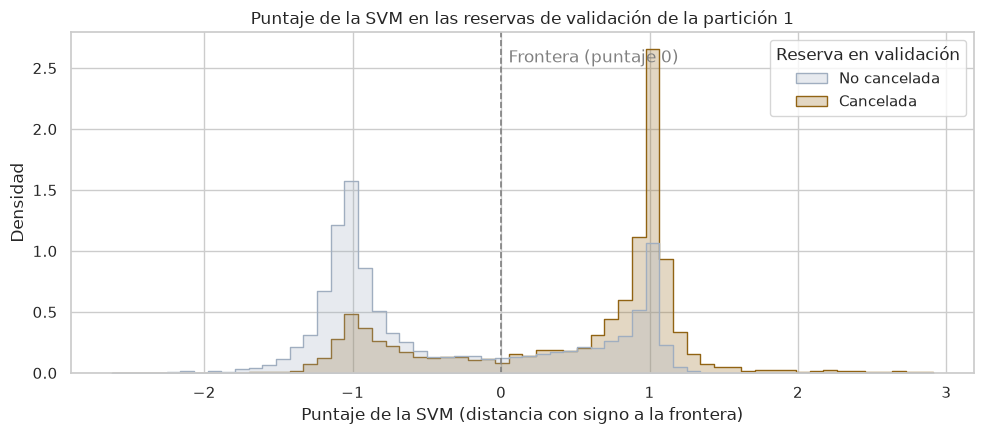

,reservas,mediana,% con puntaje > 0,% dentro del margen (entre -1 y 1)
reserva,,,,
No cancelada,8969,-0.83,34.37,56.27
Cancelada,3702,0.90,74.18,59.54


In [13]:
puntajes = pd.DataFrame({
    "puntaje": svm_particion.decision_function(X_entrenamiento.iloc[validacion]),
    "reserva": y_entrenamiento.iloc[validacion].map(NOMBRES_CLASE).to_numpy(),
})

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=puntajes, x="puntaje", hue="reserva", stat="density", common_norm=False,
             bins=INTERVALOS_HISTOGRAMA, element="step",
             palette={"No cancelada": COLOR_SECUNDARIO, "Cancelada": COLOR_RIESGO}, ax=ax)
ax.axvline(0, color="gray", linestyle="--", linewidth=1.2)
ax.text(0.05, ax.get_ylim()[1] * 0.95, "Frontera (puntaje 0)", color="gray", va="top")
ax.get_legend().set_title("Reserva en validación")
ax.set_title("Puntaje de la SVM en las reservas de validación de la partición 1")
ax.set_xlabel("Puntaje de la SVM (distancia con signo a la frontera)")
ax.set_ylabel("Densidad")
plt.tight_layout()
plt.show()

resumen_puntajes = puntajes.groupby("reserva")["puntaje"].agg(
    reservas="size",
    mediana="median",
    del_lado_cancelada=lambda puntaje: (puntaje > 0).mean() * 100,
    dentro_del_margen=lambda puntaje: puntaje.abs().lt(1).mean() * 100,
).rename(columns={"del_lado_cancelada": "% con puntaje > 0",
                  "dentro_del_margen": "% dentro del margen (entre -1 y 1)"})
resumen_puntajes.loc[["No cancelada", "Cancelada"]].round(2)

**¿Qué vemos?**

- **Dos de cada tres reservas son vectores de soporte.** De las 50.680 reservas de ajuste de la partición 1, 33.127 (65,4 %) quedaron sobre el margen o del lado equivocado de la frontera, casi en la misma proporción en las dos clases (65,2 % de las no canceladas y 65,7 % de las canceladas). Cuando dos clases se separan bien, los vectores de soporte son unos pocos; aquí son la mayoría. O sea que, con lo que se sabe al reservar, las canceladas y las no canceladas se traslapan mucho.
- **Parte de ese traslape no lo puede resolver ningún modelo.** En el entrenamiento hay 1.713 perfiles, con 4.030 reservas, en los que reservas con exactamente las mismas entradas terminaron unas canceladas y otras no. Ninguna frontera puede poner a esas reservas en lados distintos.
- **En la gráfica**, las no canceladas se amontonan cerca de −1 (mediana de −0,83) y las canceladas cerca de +1 (mediana de 0,90). Los picos están justo en los bordes del margen, que es donde quedan los vectores de soporte. Entre −1 y 1, o sea dentro del margen, está el 56,27 % de las no canceladas y el 59,54 % de las canceladas.
- **Con el corte en 0**, el 74,18 % de las canceladas queda del lado de "se cancela", que es el Recall de esta partición, pero también el 34,37 % de las no canceladas cae ahí. Se ve además un grupo de no canceladas con puntaje cerca de +1: reservas que, con estas variables, se ven igual que las que se cancelan. Mover el corte cambia cuántas canceladas se detectan y cuántas falsas alarmas hay, y eso se decide en la sección 4.
- La consecuencia práctica de tantos vectores de soporte es el costo: para predecir una reserva nueva el modelo la compara con las 33.127, y tiene que guardarlas todas.

Lo que esto no permite concluir: qué variables producen el traslape. Eso se mide en la sección 5. Además, la gráfica es de una sola partición; los resultados de las cinco están en la tabla de la 3.2.

### 3.4 Comparación con la logística

Ponemos lado a lado los dos modelos con pesos balanceados, todavía solo con validación cruzada. La prueba no la tocamos. Calculamos la diferencia entre los dos en cada métrica y la comparamos con la desviación entre particiones, para saber si la diferencia es más grande que lo que cambia un modelo de una partición a otra.

In [14]:
LOGISTICA = "Logística con pesos balanceados"
SVM = "SVM con pesos balanceados"
REFERENCIA = "Referencia: todas canceladas"

comparados = resultados_validacion[resultados_validacion["modelo"].isin([REFERENCIA, LOGISTICA, SVM])]
display(tabla_validacion(comparados))

medias = resultados_validacion.pivot(index="métrica", columns="modelo", values="media")
desviaciones = resultados_validacion.pivot(index="métrica", columns="modelo", values="desviación")
diferencias = pd.DataFrame({
    "logística": medias[LOGISTICA],
    "SVM": medias[SVM],
    "diferencia (SVM − logística)": medias[SVM] - medias[LOGISTICA],
    "desviación más alta de los dos": desviaciones[[LOGISTICA, SVM]].max(axis=1),
}).loc[list(METRICAS.values())]
diferencias["diferencia / desviación"] = (
    diferencias["diferencia (SVM − logística)"].abs() / diferencias["desviación más alta de los dos"]
)
diferencias.round(3)

métrica,F1,Recall,Precision,ROC-AUC,PR-AUC
modelo,,,,,
Referencia: todas canceladas,0.452 ± 0.000,1.000 ± 0.000,0.292 ± 0.000,0.500 ± 0.000,0.292 ± 0.000
Logística con pesos balanceados,0.571 ± 0.003,0.764 ± 0.006,0.455 ± 0.002,0.751 ± 0.002,0.553 ± 0.005
SVM con pesos balanceados,0.581 ± 0.003,0.746 ± 0.004,0.476 ± 0.004,0.764 ± 0.002,0.572 ± 0.006


,logística,SVM,diferencia (SVM − logística),desviación más alta de los dos,diferencia / desviación
métrica,,,,,
F1,0.571,0.581,0.010,0.003,3.338
Recall,0.764,0.746,-0.018,0.006,3.320
Precision,0.455,0.476,0.021,0.004,4.714
ROC-AUC,0.751,0.764,0.013,0.002,6.015
PR-AUC,0.553,0.572,0.019,0.006,3.339


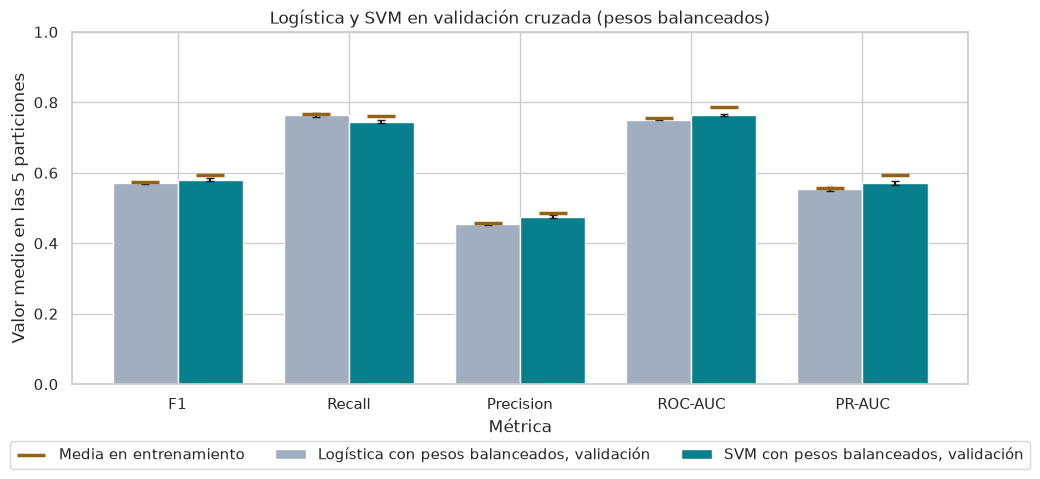

In [15]:
etiquetas_metricas = list(METRICAS.values())
posiciones = np.arange(len(etiquetas_metricas))
ancho = 0.38
modelos_grafica = {LOGISTICA: COLOR_SECUNDARIO, SVM: COLOR_PRINCIPAL}

fig, ax = plt.subplots(figsize=(11, 5))
for desplazamiento, (modelo, color) in zip((-ancho / 2, ancho / 2), modelos_grafica.items()):
    datos = resultados_validacion[resultados_validacion["modelo"] == modelo].set_index("métrica").loc[etiquetas_metricas]
    ax.bar(posiciones + desplazamiento, datos["media"], ancho, yerr=datos["desviación"],
           color=color, capsize=3, label=f"{modelo}, validación")
    ax.scatter(posiciones + desplazamiento, datos["media en entrenamiento"], color=COLOR_RIESGO,
               marker="_", s=400, linewidths=2.5, zorder=3)
ax.scatter([], [], color=COLOR_RIESGO, marker="_", s=400, linewidths=2.5, label="Media en entrenamiento")
ax.set_xticks(posiciones, etiquetas_metricas)
ax.set_ylim(0, 1)
ax.set_title("Logística y SVM en validación cruzada (pesos balanceados)")
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor medio en las 5 particiones")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **La SVM le gana a la logística en cuatro de las cinco métricas:** F1 de 0,581 contra 0,571, Precision de 0,476 contra 0,455, ROC-AUC de 0,764 contra 0,751 y PR-AUC de 0,572 contra 0,553. Solo pierde en Recall, 0,746 contra 0,764: con el corte por defecto marca un poco menos de reservas como canceladas, pero acierta más cuando las marca. Como el Recall y la Precision dependen del umbral, esa diferencia puede cambiar en la sección 4.
- **Las diferencias son pequeñas, pero no son ruido.** Van de 0,010 a 0,021, y todas son al menos 3,3 veces la desviación entre particiones; en el ROC-AUC son 6,0 veces. Como los dos modelos se validaron en las mismas particiones, la ventaja no se explica por una partición que le haya caído bien a uno.
- **Lo que no depende del umbral favorece a la SVM.** Ordena mejor las reservas de más a menos riesgo (ROC-AUC) y encuentra mejor las canceladas (PR-AUC). Es la ganancia que esperábamos de una frontera curva, porque la logística no podía seguir la forma de la anticipación.
- **La ganancia es modesta**: el ROC-AUC sube de 0,751 a 0,764. Junto con el traslape de la 3.3, eso dice que lo que más limita la predicción no es la forma del modelo, sino la poca información que hay al momento de reservar.
- En la gráfica, las rayas ocres de la SVM quedan un poco más arriba de sus barras que las de la logística (0,787 contra 0,764 de ROC-AUC, frente a 0,754 contra 0,751), pero siguen cerca. Las barras de error son muy cortas en los dos modelos.

### 3.5 Cierre de la SVM

- Cambiamos el bosque aleatorio del plan por una SVM con kernel RBF, que es uno de los modelos supervisados de la guía de las semanas 12-13. Su frontera curva puede seguir la forma de la anticipación y las noches y las interacciones entre variables, que la logística no captaba.
- Con la configuración por defecto (`C=1`, `gamma="scale"`) y pesos balanceados, en validación cruzada obtiene un F1 de 0,581, Recall de 0,746, Precision de 0,476, ROC-AUC de 0,764 y PR-AUC de 0,572, con poco sobreajuste.
- Le gana a la logística en F1, Precision, ROC-AUC y PR-AUC, por poco pero de forma consistente: las diferencias son entre 3,3 y 6,0 veces la desviación entre particiones. Pierde un poco en Recall con el corte por defecto.
- Las clases se traslapan mucho: el 65,4 % de las reservas de ajuste terminan como vectores de soporte. Eso limita lo que cualquier modelo puede lograr con estas variables y hace que la SVM sea lenta para entrenar y para predecir.

Lo que esta comparación no permite concluir: que la SVM sea mejor que la logística en general. Ninguno de los dos está ajustado todavía y la diferencia es pequeña. Tampoco dice qué variables usa la SVM, que con este kernel no tiene coeficientes; eso se mide en la sección 5 con la importancia por permutación, que funciona igual para los dos modelos. Y, como todo lo anterior, son asociaciones, no causas.

Para la sección 4 quedan tres cosas. Los hiperparámetros de la SVM son `C` y `gamma`, y como cada validación tarda varios minutos, la búsqueda tiene que ser de pocas combinaciones. El umbral de la SVM se escoge sobre su puntaje (`decision_function`), porque no da probabilidades. Y `crear_svm` y `resultados_validacion` quedan listos para esa sección.

## 4. Ajuste de hiperparámetros y evaluación en prueba

Hasta aquí los dos modelos usan la configuración por defecto de scikit-learn y el corte por defecto. En esta sección hacemos cuatro cosas, en este orden:

1. Buscamos los hiperparámetros de cada modelo con validación cruzada, solo con entrenamiento: `C` en la logística, como quedó dicho en la 2.1, y `C` y `gamma` en la SVM.
2. Escogemos el umbral de decisión de cada modelo, también con validación cruzada.
3. Con eso decidimos qué modelo va a prueba.
4. Evaluamos en prueba una sola vez y miramos qué le cuesta al hotel cada tipo de error.

El orden importa. Si mirábamos la prueba antes de escoger hiperparámetros, umbral o modelo, cualquiera de esas decisiones quedaba acomodada a esas 15.839 reservas y el resultado final salía más optimista de lo que es. Por eso la prueba se carga recién en la 4.5, cuando ya no queda nada por decidir.

Para buscar hiperparámetros usamos el ROC-AUC y no el F1. El F1 depende del corte, y con el corte por defecto mezclaría dos decisiones: qué tan bien ordena el modelo y dónde cortamos. El ROC-AUC solo mide lo primero, y el corte lo escogemos aparte en la 4.3. Todas las búsquedas usan las mismas cinco `particiones` agrupadas por perfil de la sección 1 y mantienen `class_weight="balanced"`, la decisión de la 2.3 y la 3.2.

In [16]:
from joblib import parallel_config
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, cross_val_predict

RUTA_PRUEBA = Path("../data/processed/prueba.csv.gz")
METRICAS_BUSQUEDA = {"roc_auc": "ROC-AUC", "average_precision": "PR-AUC"}
METRICA_BUSQUEDA = "roc_auc"
VALORES_C_LOGISTICA = [0.01, 0.1, 1, 10, 100]
VALORES_C_SVM = [0.3, 1, 3]
VALORES_GAMMA_SVM = [0.02, "scale", 0.2]
RAZONES_COSTO = [0.5, 1, 2, 3]
RESERVAS_REFERENCIA = 1_000
SEGUNDOS_POR_MINUTO = 60

LOGISTICA_AJUSTADA = "Logística ajustada"
SVM_AJUSTADA = "SVM ajustada"
COLORES_MODELO = {LOGISTICA_AJUSTADA: COLOR_SECUNDARIO, SVM_AJUSTADA: COLOR_PRINCIPAL}


def buscar_hiperparametros(modelo, rejilla):
    """Búsqueda en rejilla con las particiones fijas; reajusta el mejor con todo el entrenamiento."""
    busqueda = GridSearchCV(modelo, rejilla, cv=particiones, scoring=list(METRICAS_BUSQUEDA),
                            refit=METRICA_BUSQUEDA, return_train_score=True)
    with parallel_config(n_jobs=-1):
        busqueda.fit(X_entrenamiento, y_entrenamiento)
    return busqueda


def tabla_busqueda(busqueda):
    """Una fila por combinación con sus métricas en validación, en entrenamiento y su tiempo."""
    resultados = pd.DataFrame(busqueda.cv_results_)
    tabla = pd.DataFrame({
        nombre.removeprefix("modelo__"): [str(parametros[nombre]) for parametros in resultados["params"]]
        for nombre in busqueda.param_grid
    })
    for clave, etiqueta in METRICAS_BUSQUEDA.items():
        tabla[f"{etiqueta} validación"] = resultados[f"mean_test_{clave}"]
        tabla[f"{etiqueta} desviación"] = resultados[f"std_test_{clave}"]
    tabla["ROC-AUC entrenamiento"] = resultados["mean_train_roc_auc"]
    tabla["minutos por ajuste"] = resultados["mean_fit_time"] / SEGUNDOS_POR_MINUTO
    return tabla.sort_values("ROC-AUC validación", ascending=False)

### 4.1 La `C` de la logística

En la logística `C` es el inverso de la fuerza de la regularización L2: con `C` pequeño los coeficientes se encogen más hacia cero y con `C` grande el modelo queda casi sin regularizar. Probamos cinco valores, de 0,01 a 100, separados por un factor de 10. La logística entrena en segundos, así que aquí la rejilla puede ser amplia.

In [17]:
busqueda_logistica = buscar_hiperparametros(crear_logistica("balanced"), {"modelo__C": VALORES_C_LOGISTICA})
display(tabla_busqueda(busqueda_logistica).round(4))
print(f"Mejor C de la logística: {busqueda_logistica.best_params_['modelo__C']}")

,C,ROC-AUC validación,ROC-AUC desviación,PR-AUC validación,PR-AUC desviación,ROC-AUC entrenamiento,minutos por ajuste
2,1,0.7509,0.0021,0.5534,0.0051,0.7544,0.0258
4,100,0.7508,0.0022,0.5532,0.0052,0.7546,0.0264
3,10,0.7508,0.0022,0.5532,0.0050,0.7545,0.0343
1,0.1,0.7501,0.0019,0.5520,0.0050,0.7529,0.0264
0,0.01,0.7453,0.0019,0.5449,0.0047,0.7470,0.0120


Mejor C de la logística: 1


**¿Qué vemos?**

La `C` casi no le mueve nada a la logística. Entre `C=0.1` y `C=100` el ROC-AUC en validación va de 0,7501 a 0,7509, diferencias muy por debajo de la desviación entre particiones, que es de unas 0,002. Solo con `C=0.01`, que la regulariza mucho, baja a 0,7453. La mejor sale `C=1`, que es justo la que ya traía, así que lo de la sección 2 queda valiendo tal cual.

Tiene sentido. Con 63.351 reservas para 163 columnas después del one-hot, hay datos de sobra para estimar los coeficientes y la regularización tiene poco que corregir. Además, la diferencia entre entrenamiento y validación es de milésimas (0,7544 contra 0,7509 con `C=1`), o sea que no hay sobreajuste que frenar. Lo que limita a la logística es que es lineal, como se vio en la 2.2. Cada ajuste tarda menos de tres segundos (0,0343 minutos el más lento).

### 4.2 `C` y `gamma` de la SVM

En la SVM los dos hiperparámetros se mueven juntos. `C` es el castigo por cada reserva que queda del lado equivocado o dentro del margen, y `gamma` dice qué tan rápido se pierde el parecido entre dos reservas con la distancia: con `gamma` grande cada reserva solo influye en sus vecinas más cercanas y la frontera se puede doblar mucho, y con `gamma` pequeño la frontera queda más suave. Un `gamma` grande con un `C` grande es la combinación que más se presta para sobreajustar.

Como cada ajuste tarda unos minutos, usamos una rejilla de 3 × 3, con nueve combinaciones y 45 ajustes en total. Ponemos el valor por defecto en el centro (`C=1` y `gamma="scale"`) y a cada lado un valor unas tres veces menor y otro unas tres veces mayor, en escala logarítmica, que es como cambian el efecto de estos parámetros. Para saber a qué número corresponde `"scale"` lo calculamos con todo el entrenamiento transformado: scikit-learn usa 1 / (número de columnas × varianza de la matriz). En cada partición el valor cambia un poco porque el preprocesador se ajusta con otras filas.

Una rejilla de 3 × 3 no garantiza encontrar el mejor par posible. Lo que sí deja ver es si mover `C` o `gamma` desde el valor por defecto mejora algo, y hacia qué lado. Esta celda es la más lenta del notebook: en nuestro computador, con 12 núcleos trabajando en paralelo, tardó más de una hora. Ojo con eso si les toca volver a correr todo el notebook.

In [18]:
matriz_entrenamiento = crear_preprocesador().fit_transform(X_entrenamiento)
varianza = matriz_entrenamiento.multiply(matriz_entrenamiento).mean() - matriz_entrenamiento.mean() ** 2
gamma_scale = 1 / (matriz_entrenamiento.shape[1] * varianza)
print(f"gamma='scale' con todo el entrenamiento: {gamma_scale:.4f}")

busqueda_svm = buscar_hiperparametros(
    crear_svm("balanced"),
    {"modelo__C": VALORES_C_SVM, "modelo__gamma": VALORES_GAMMA_SVM},
)
resultados_busqueda_svm = tabla_busqueda(busqueda_svm)
display(resultados_busqueda_svm.round(4))
print(f"Mejor combinación de la SVM: {busqueda_svm.best_params_}")

gamma='scale' con todo el entrenamiento: 0.0568


,C,gamma,ROC-AUC validación,ROC-AUC desviación,PR-AUC validación,PR-AUC desviación,ROC-AUC entrenamiento,minutos por ajuste
7,3,scale,0.7674,0.0017,0.5748,0.0049,0.8029,15.7619
4,1,scale,0.7639,0.0020,0.5720,0.0056,0.7869,17.0095
5,1,0.2,0.7621,0.0022,0.5432,0.0037,0.8304,14.2594
6,3,0.02,0.7613,0.0026,0.5747,0.0058,0.7754,9.6373
2,0.3,0.2,0.7594,0.0017,0.5412,0.0038,0.8003,22.0274
1,0.3,scale,0.7582,0.0021,0.5651,0.0058,0.7714,12.7316
8,3,0.2,0.7577,0.0025,0.5362,0.0031,0.8597,18.3571
3,1,0.02,0.7564,0.0024,0.5687,0.0054,0.7651,19.7540
0,0.3,0.02,0.7480,0.0023,0.5596,0.0054,0.7528,10.9948


Mejor combinación de la SVM: {'modelo__C': 3, 'modelo__gamma': 'scale'}


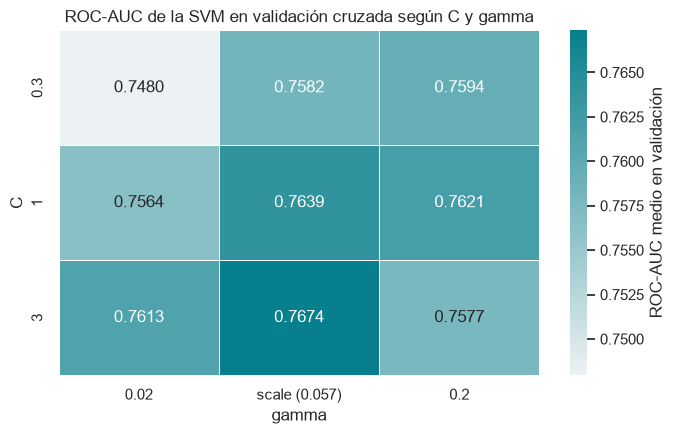

In [19]:
etiqueta_gamma = {str(valor): f"{valor} ({gamma_scale:.3f})" if valor == "scale" else str(valor)
                  for valor in VALORES_GAMMA_SVM}
rejilla_svm = resultados_busqueda_svm.assign(gamma=resultados_busqueda_svm["gamma"].map(etiqueta_gamma)).pivot(
    index="C", columns="gamma", values="ROC-AUC validación"
).loc[[str(valor) for valor in VALORES_C_SVM], list(etiqueta_gamma.values())]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(rejilla_svm, annot=True, fmt=".4f", cmap=sns.light_palette(COLOR_PRINCIPAL, as_cmap=True),
            linewidths=0.5, cbar_kws={"label": "ROC-AUC medio en validación"}, ax=ax)
ax.set_title("ROC-AUC de la SVM en validación cruzada según C y gamma")
ax.set_xlabel("gamma")
ax.set_ylabel("C")
plt.tight_layout()
plt.show()

**¿Qué vemos?**

La mejor combinación es `C=3` con `gamma="scale"` (0,057), con un ROC-AUC de 0,7674 en validación, contra 0,7639 de la configuración por defecto que usó la sección 3. La mejora es pequeña, 0,0035, pero es más o menos el doble de la desviación entre particiones (0,0017 y 0,0020). En PR-AUC pasa de 0,5720 a 0,5748.

La rejilla deja ver bien qué hace `gamma`. Con `gamma=0.2` el modelo se aprende el entrenamiento: su ROC-AUC en entrenamiento llega a 0,8597 con `C=3`, pero en validación baja a 0,7577, y su PR-AUC es el más bajo de toda la tabla (entre 0,5362 y 0,5432). Esa es la frontera demasiado curva de la que hablamos arriba. Con `gamma=0.02` pasa lo contrario: la frontera queda tan suave que con `C=0.3` cae a 0,7480, casi lo mismo que la logística. El valor de `"scale"` queda en el medio y es el mejor con `C=1` y con `C=3`.

Ojo con dos cosas. La primera es que el mejor par quedó en el borde de la rejilla, con el `C` más grande que probamos, así que puede que con `C=10` mejorara un poco más. No lo probamos porque cada ajuste ya tardó entre 10 y 22 minutos en nuestro computador. La segunda es que con `C=3` el sobreajuste crece un poco: la distancia entre entrenamiento y validación pasa de 0,0230 (0,7869 contra 0,7639) a 0,0355 (0,8029 contra 0,7674). Sigue siendo pequeña, y lo que cuenta es que la validación subió.

### 4.3 El umbral de decisión

Los dos modelos entregan un puntaje: la logística, el logit de cancelar (`decision_function`), y la SVM, la distancia con signo a la frontera. Por defecto se marca como cancelada toda reserva con puntaje mayor que 0. Ese corte no tiene nada de especial para el hotel, así que lo escogemos.

Para escogerlo sin tocar la prueba necesitamos puntajes de reservas que el modelo no vio. Con `cross_val_predict` cada reserva de entrenamiento recibe el puntaje del modelo que se ajustó en las otras cuatro particiones. Sobre esos puntajes, que llamamos fuera de partición, probamos todos los cortes posibles.

El criterio es **el corte que maximiza el F1**. El F1 es la media armónica de Precision y Recall, así que solo sube si suben las dos, y es la métrica principal del enunciado. Eso sí, el F1 no le pone un precio a cada error. En la 4.6 miramos a qué relación de costos equivale este corte y qué pasa si el hotel pesa los errores distinto.

Una precaución: juntamos los puntajes de cinco modelos distintos, uno por partición, que pueden tener escalas un poco diferentes. Por eso, además del F1 con todos los puntajes juntos, revisamos el F1 de cada partición con ese mismo corte.

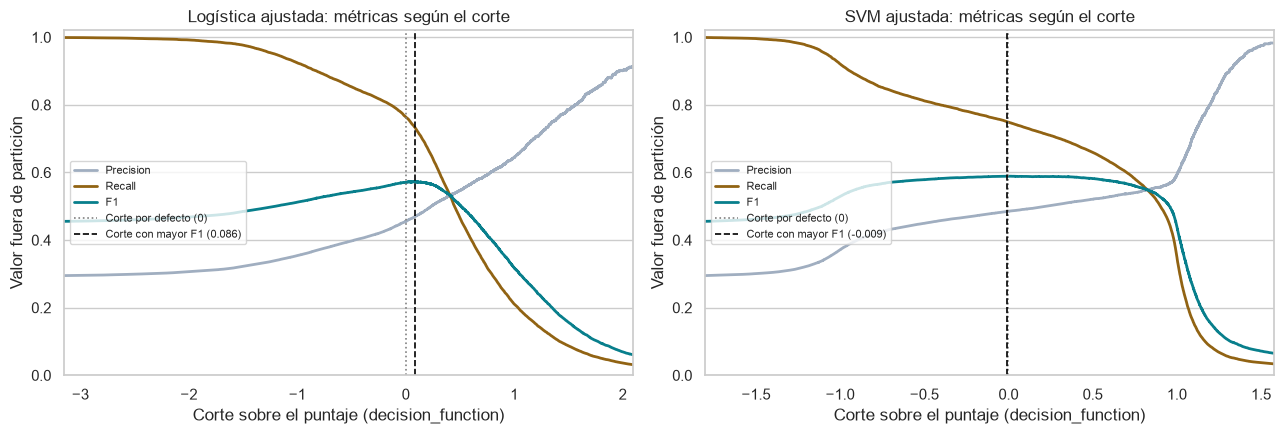

In [20]:
modelos_ajustados = {
    LOGISTICA_AJUSTADA: busqueda_logistica.best_estimator_,
    SVM_AJUSTADA: busqueda_svm.best_estimator_,
}

with parallel_config(n_jobs=-1):
    puntajes_validacion = {
        nombre: cross_val_predict(modelo, X_entrenamiento, y_entrenamiento, cv=particiones,
                                  method="decision_function")
        for nombre, modelo in modelos_ajustados.items()
    }


def curva_de_umbrales(y, puntajes):
    """Precision, Recall y F1 para cada corte posible del puntaje."""
    precision, recall, umbrales = precision_recall_curve(y, puntajes)
    curva = pd.DataFrame({"umbral": umbrales, "precision": precision[:-1], "recall": recall[:-1]})
    suma = curva["precision"] + curva["recall"]
    curva["f1"] = np.where(suma > 0, 2 * curva["precision"] * curva["recall"] / suma.where(suma > 0, 1), 0)
    return curva


curvas = {nombre: curva_de_umbrales(y_entrenamiento, puntajes) for nombre, puntajes in puntajes_validacion.items()}
umbrales = {nombre: curva.loc[curva["f1"].idxmax(), "umbral"] for nombre, curva in curvas.items()}

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (nombre, curva) in zip(ejes, curvas.items()):
    ax.plot(curva["umbral"], curva["precision"], color=COLOR_SECUNDARIO, linewidth=2, label="Precision")
    ax.plot(curva["umbral"], curva["recall"], color=COLOR_RIESGO, linewidth=2, label="Recall")
    ax.plot(curva["umbral"], curva["f1"], color=COLOR_PRINCIPAL, linewidth=2, label="F1")
    ax.axvline(0, color="gray", linestyle=":", linewidth=1.2, label="Corte por defecto (0)")
    ax.axvline(umbrales[nombre], color="black", linestyle="--", linewidth=1.2,
               label=f"Corte con mayor F1 ({umbrales[nombre]:.3f})")
    ax.set_xlim(np.percentile(puntajes_validacion[nombre], [1, 99]))
    ax.set_ylim(0, 1.02)
    ax.set_title(f"{nombre}: métricas según el corte")
    ax.set_xlabel("Corte sobre el puntaje (decision_function)")
    ax.set_ylabel("Valor fuera de partición")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()

In [21]:
def metricas_con_corte(y, puntajes, umbral):
    """F1, Recall y Precision con un corte, y ROC-AUC y PR-AUC del puntaje."""
    marcadas = puntajes >= umbral
    return {
        "F1": f1_score(y, marcadas),
        "Recall": recall_score(y, marcadas),
        "Precision": precision_score(y, marcadas),
        "ROC-AUC": roc_auc_score(y, puntajes),
        "PR-AUC": average_precision_score(y, puntajes),
        "% marcadas como canceladas": marcadas.mean() * 100,
    }


def metricas_por_particion(nombre, umbral):
    """Métricas en la validación de cada partición con un corte fijo."""
    puntajes = puntajes_validacion[nombre]
    return pd.DataFrame([
        metricas_con_corte(y_entrenamiento.iloc[validacion], puntajes[validacion], umbral)
        for _, validacion in particiones
    ])


filas = []
for nombre in modelos_ajustados:
    for corte, umbral in (("por defecto (0)", 0.0), ("con mayor F1", umbrales[nombre])):
        por_particion = metricas_por_particion(nombre, umbral)
        fila = {"modelo": nombre, "corte": corte, "umbral": umbral}
        for metrica in ("F1", "Recall", "Precision", "% marcadas como canceladas"):
            fila[metrica] = por_particion[metrica].mean()
            if metrica == "F1":
                fila["F1 desviación"] = por_particion[metrica].std(ddof=0)
        filas.append(fila)
comparacion_cortes = pd.DataFrame(filas).set_index(["modelo", "corte"])
comparacion_cortes.round(3)

umbral     F1  F1 desviación  Recall  \
modelo             corte                                                   
Logística ajustada por defecto (0)   0.000  0.571          0.003   0.764   
                   con mayor F1      0.086  0.573          0.002   0.733   
SVM ajustada       por defecto (0)   0.000  0.589          0.003   0.749   
                   con mayor F1     -0.009  0.589          0.003   0.750   

                                    Precision  % marcadas como canceladas  
modelo             corte                                                   
Logística ajustada por defecto (0)      0.455                      49.049  
                   con mayor F1         0.470                      45.559  
SVM ajustada       por defecto (0)      0.485                      45.087  
                   con mayor F1         0.485                      45.229

**¿Qué vemos?**

En la SVM el mejor corte es casi el mismo de por defecto: −0,009 contra 0, con el mismo F1 de 0,589. Era de esperar, porque con `class_weight="balanced"` las dos clases ya pesan lo mismo en el ajuste y la frontera queda más o menos donde el F1 es máximo. En la gráfica se ve que la curva del F1 de la SVM es casi plana alrededor de 0: mover un poco el corte cambia el reparto entre Recall y Precision, pero casi no cambia el F1.

En la logística el corte sí se mueve, a 0,086, y el F1 sube apenas de 0,571 a 0,573. El modelo marca menos reservas (45,6 % en vez de 49,0 %), pierde Recall (de 0,764 a 0,733) y gana Precision (de 0,455 a 0,470).

Con el corte escogido, el F1 casi no cambia entre particiones: la desviación es de 0,002 en la logística y de 0,003 en la SVM. O sea que juntar los puntajes de los cinco modelos no llevó el corte a un lugar raro.

### 4.4 Qué modelo va a prueba

Antes de cargar la prueba dejamos escrita la regla: va el modelo con mayor F1 medio en validación cruzada, cada uno con su corte de la 4.3. Usamos el F1 porque es la métrica que combina las dos cosas que le importan al hotel con el corte con el que de verdad se usaría el modelo. El ROC-AUC y el PR-AUC quedan como apoyo. El otro modelo también se evalúa en prueba, en la misma celda y una sola vez, pero solo como referencia: su resultado ya no puede cambiar la decisión.

In [22]:
resumen_validacion = pd.DataFrame({
    nombre: metricas_por_particion(nombre, umbrales[nombre]).agg(["mean", "std"]).T.apply(
        lambda fila: f"{fila['mean']:.3f} ± {fila['std']:.3f}", axis=1)
    for nombre in modelos_ajustados
}).T
resumen_validacion.insert(0, "umbral", [f"{umbrales[nombre]:.3f}" for nombre in resumen_validacion.index])
display(resumen_validacion)

f1_validacion = {nombre: metricas_por_particion(nombre, umbrales[nombre])["F1"].mean() for nombre in modelos_ajustados}
MODELO_FINAL = max(f1_validacion, key=f1_validacion.get)
modelo_final = modelos_ajustados[MODELO_FINAL]
umbral_final = umbrales[MODELO_FINAL]
print(f"Modelo que va a prueba: {MODELO_FINAL}, con corte {umbral_final:.3f}")

,umbral,F1,Recall,Precision,ROC-AUC,PR-AUC,% marcadas como canceladas
Logística ajustada,0.086,0.573 ± 0.002,0.733 ± 0.007,0.470 ± 0.002,0.751 ± 0.002,0.553 ± 0.006,45.559 ± 0.533
SVM ajustada,-0.009,0.589 ± 0.003,0.750 ± 0.005,0.485 ± 0.003,0.767 ± 0.002,0.575 ± 0.006,45.229 ± 0.365


Modelo que va a prueba: SVM ajustada, con corte -0.009


**¿Qué vemos?**

Va la SVM ajustada. Con su corte tiene un F1 de 0,589 contra 0,573 de la logística, una diferencia de 0,016, que es más de cinco veces la desviación entre particiones. También gana en Recall (0,750 contra 0,733), Precision (0,485 contra 0,470), ROC-AUC (0,767 contra 0,751) y PR-AUC (0,575 contra 0,553), y las dos marcan más o menos la misma proporción de reservas (45,2 % y 45,6 %). Así que no toca escoger entre detectar más o equivocarse menos: la SVM hace las dos cosas un poco mejor.

Lo que le cuesta es que es mucho más lenta y no se puede leer como la logística. Si el hotel necesitara explicar por qué marcó una reserva, la logística seguiría siendo una opción razonable, con un F1 apenas 0,016 menor. Esa discusión queda para la comparación del notebook 05.

### 4.5 Evaluación en prueba

Ya están escogidos los hiperparámetros, los cortes y el modelo, así que ahora sí cargamos la prueba. Los dos modelos se reajustaron con todo el entrenamiento al terminar su búsqueda (`refit` de `GridSearchCV`). Aquí solo calculamos sus puntajes en prueba, aplicamos los cortes de la 4.3 y comparamos con lo que esperábamos por validación cruzada.

In [23]:
prueba = pd.read_csv(RUTA_PRUEBA)
X_prueba = prueba[list(COLUMNAS_PREDICTORAS)]
y_prueba = prueba[OBJETIVO]
assert set(prueba[GRUPO]).isdisjoint(entrenamiento[GRUPO])
print(f"Prueba: {len(prueba):,} reservas, {y_prueba.mean():.1%} canceladas")

puntajes_prueba = {nombre: modelo.decision_function(X_prueba) for nombre, modelo in modelos_ajustados.items()}

filas = []
for nombre in modelos_ajustados:
    en_validacion = metricas_por_particion(nombre, umbrales[nombre]).mean()
    en_prueba = metricas_con_corte(y_prueba, puntajes_prueba[nombre], umbrales[nombre])
    for metrica in ("F1", "Recall", "Precision", "ROC-AUC", "PR-AUC"):
        filas.append({"modelo": nombre, "métrica": metrica,
                      "validación cruzada": en_validacion[metrica], "prueba": en_prueba[metrica]})
evaluacion_prueba = pd.DataFrame(filas)
evaluacion_prueba["diferencia"] = evaluacion_prueba["prueba"] - evaluacion_prueba["validación cruzada"]
evaluacion_prueba.set_index(["modelo", "métrica"]).round(3)

Prueba: 15,839 reservas, 29.2% canceladas


validación cruzada  prueba  diferencia
modelo             métrica                                          
Logística ajustada F1                      0.573   0.575       0.002
                   Recall                  0.733   0.736       0.003
                   Precision               0.470   0.471       0.001
                   ROC-AUC                 0.751   0.754       0.003
                   PR-AUC                  0.553   0.559       0.006
SVM ajustada       F1                      0.589   0.590       0.001
                   Recall                  0.750   0.750      -0.001
                   Precision               0.485   0.486       0.002
                   ROC-AUC                 0.767   0.771       0.003
                   PR-AUC                  0.575   0.579       0.004

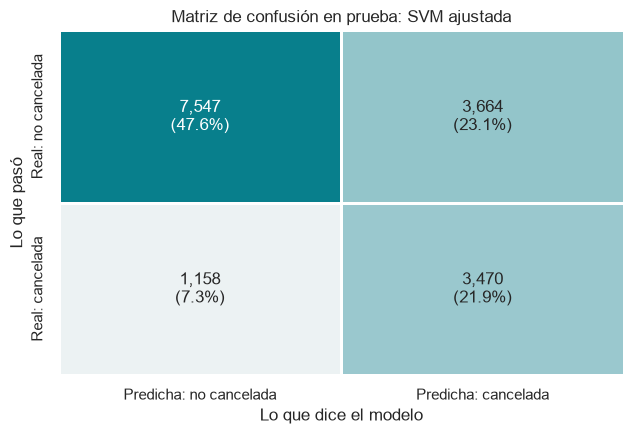

Canceladas detectadas: 3,470 de 4,628
Falsas alarmas: 3,664 de 11,211 reservas que sí llegaron
Reservas marcadas como canceladas: 7,134 (45.0%)


In [24]:
marcadas_final = puntajes_prueba[MODELO_FINAL] >= umbral_final
matriz = pd.DataFrame(
    confusion_matrix(y_prueba, marcadas_final),
    index=["Real: no cancelada", "Real: cancelada"],
    columns=["Predicha: no cancelada", "Predicha: cancelada"],
)
anotaciones = matriz.map(lambda valor: f"{valor:,}\n({valor / len(y_prueba):.1%})")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(matriz, annot=anotaciones, fmt="", cmap=sns.light_palette(COLOR_PRINCIPAL, as_cmap=True),
            cbar=False, linewidths=1, ax=ax)
ax.set_title(f"Matriz de confusión en prueba: {MODELO_FINAL}")
ax.set_xlabel("Lo que dice el modelo")
ax.set_ylabel("Lo que pasó")
plt.tight_layout()
plt.show()

verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = matriz.to_numpy().ravel()
print(f"Canceladas detectadas: {verdaderos_positivos:,} de {verdaderos_positivos + falsos_negativos:,}")
print(f"Falsas alarmas: {falsos_positivos:,} de {verdaderos_negativos + falsos_positivos:,} reservas que sí llegaron")
print(f"Reservas marcadas como canceladas: {marcadas_final.sum():,} ({marcadas_final.mean():.1%})")

**¿Qué vemos?**

En prueba la SVM saca un F1 de 0,590, Recall de 0,750, Precision de 0,486, ROC-AUC de 0,771 y PR-AUC de 0,579. Son prácticamente los mismos números de la validación cruzada: la diferencia más grande es de 0,004. Eso era lo que queríamos ver, porque quiere decir que las decisiones de esta sección no quedaron acomodadas al entrenamiento y que la validación agrupada por perfil estimó bien. La logística también aguanta (F1 de 0,575 en prueba contra 0,573 en validación), y la SVM le sigue ganando en todas las métricas, igual que en validación.

En la matriz de confusión: de las 4.628 reservas de prueba que se cancelaron, el modelo detecta 3.470 y se le escapan 1.158. A cambio, de las 11.211 que sí llegaron marca 3.664 como riesgosas. En total marca el 45,0 % de las reservas, y de las que marca se cancela el 48,6 %, contra el 29,2 % de todas las reservas de prueba.

Eso es lo que significa un F1 de 0,59 en la práctica. El modelo sirve para priorizar, porque las reservas que marca se cancelan bastante más que el promedio. Pero se equivoca en más de la mitad de las que marca, así que no da para tomar decisiones duras sobre una reserva sola, como cancelarla o sobrevenderla sin más.

Lo que esto no permite concluir: la prueba sale de las mismas reservas de 2015 a 2017, partidas por perfil, no de reservas futuras. Si el modelo aguanta con reservas de otro año se mide en la validación temporal de la sección 6.

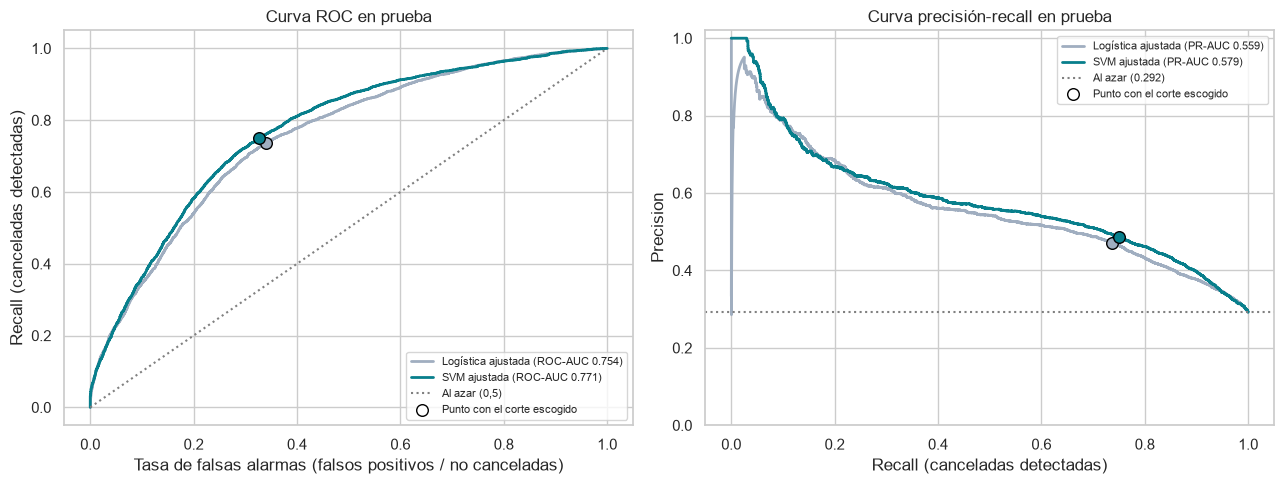

In [25]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))
for nombre, puntajes in puntajes_prueba.items():
    marcadas = puntajes >= umbrales[nombre]
    tasa_falsos, tasa_verdaderos, _ = roc_curve(y_prueba, puntajes)
    ax_roc.plot(tasa_falsos, tasa_verdaderos, color=COLORES_MODELO[nombre], linewidth=2,
                label=f"{nombre} (ROC-AUC {roc_auc_score(y_prueba, puntajes):.3f})")
    ax_roc.scatter(marcadas[y_prueba == 0].mean(), marcadas[y_prueba == 1].mean(),
                   color=COLORES_MODELO[nombre], edgecolor="black", s=70, zorder=3)
    precision, recall, _ = precision_recall_curve(y_prueba, puntajes)
    ax_pr.plot(recall, precision, color=COLORES_MODELO[nombre], linewidth=2,
               label=f"{nombre} (PR-AUC {average_precision_score(y_prueba, puntajes):.3f})")
    ax_pr.scatter(recall_score(y_prueba, marcadas), precision_score(y_prueba, marcadas),
                  color=COLORES_MODELO[nombre], edgecolor="black", s=70, zorder=3)

ax_roc.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Al azar (0,5)")
ax_roc.set_title("Curva ROC en prueba")
ax_roc.set_xlabel("Tasa de falsas alarmas (falsos positivos / no canceladas)")
ax_roc.set_ylabel("Recall (canceladas detectadas)")
ax_pr.axhline(y_prueba.mean(), color="gray", linestyle=":", label=f"Al azar ({y_prueba.mean():.3f})")
ax_pr.set_title("Curva precisión-recall en prueba")
ax_pr.set_xlabel("Recall (canceladas detectadas)")
ax_pr.set_ylabel("Precision")
ax_pr.set_ylim(0, 1.02)
for ax in (ax_roc, ax_pr):
    ax.scatter([], [], color="white", edgecolor="black", s=70, label="Punto con el corte escogido")
    ax.legend(loc="lower right" if ax is ax_roc else "upper right", fontsize=8)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

La curva ROC de la SVM queda por encima de la de la logística casi en todo el recorrido, con un ROC-AUC de 0,771 contra 0,754, aunque en los extremos las dos casi se tocan. Los puntos muestran dónde trabaja cada modelo con su corte: los dos detectan unas tres de cada cuatro cancelaciones, y la SVM lo hace con un poco menos de falsas alarmas.

En la curva precisión-recall, la línea punteada es lo que daría marcar al azar (0,292, la tasa de cancelación de prueba). Las dos curvas quedan bien por encima, con un PR-AUC de 0,579 y 0,559. Al principio, con muy poco Recall, la Precision es alta: las reservas con el puntaje más alto casi siempre se cancelan. Pero esa zona es chiquita. Para detectar la mayoría de las cancelaciones toca bajar a una Precision cercana a 0,5, que es donde queda el corte escogido.

### 4.6 Qué le cuesta al hotel cada error

Los dos errores tienen costos distintos, y dependen de qué haga el hotel con la predicción.

Un **falso negativo** es una reserva que el modelo da por segura y se cancela. El hotel no se prepara: si la cancelación llega tarde, la habitación queda vacía esa noche y esa plata se pierde, porque una noche de hotel no se puede vender después. Es el costo que el modelo quiere evitar.

Un **falso positivo** es una reserva que el modelo marca como riesgosa y el cliente sí llega. Cuánto cuesta depende de la acción. Si el hotel solo llama a confirmar, cuesta una llamada y quizás algo de molestia. Si pide un depósito, puede espantar a un cliente que sí iba a llegar. Y si cuenta esa habitación dentro de la sobreventa, puede quedarse sin cuarto para un huésped que llega, lo que obliga a reubicarlo en otro hotel y pagar el traslado.

No tenemos los costos reales de estos hoteles. Además, el notebook 02 dejó la tarifa por fuera, así que ni siquiera podemos estimar cuánto vale una noche perdida. Lo que sí podemos hacer es ver cómo cambiaría el corte si un error pesara más que el otro. Con los puntajes fuera de partición del modelo escogido, para cada razón entre el costo de un falso negativo y el de un falso positivo buscamos el corte que hace mínimo el costo total. Todo esto es con entrenamiento: la prueba ya se usó y no la volvemos a usar para decidir nada.

In [26]:
def corte_de_menor_costo(y, puntajes, razon):
    """Corte que minimiza falsos positivos + razón × falsos negativos."""
    tasa_falsos, tasa_verdaderos, cortes = roc_curve(y, puntajes)
    positivas, negativas = y.sum(), (1 - y).sum()
    costo = tasa_falsos * negativas + razon * (1 - tasa_verdaderos) * positivas
    return cortes[np.argmin(costo)]


puntajes_final = puntajes_validacion[MODELO_FINAL]
filas = []
for razon in RAZONES_COSTO:
    corte = corte_de_menor_costo(y_entrenamiento, puntajes_final, razon)
    marcadas = puntajes_final >= corte
    escala = RESERVAS_REFERENCIA / len(y_entrenamiento)
    filas.append({
        "un falso negativo cuesta (× un falso positivo)": razon,
        "corte": corte,
        "Recall": recall_score(y_entrenamiento, marcadas),
        "Precision": precision_score(y_entrenamiento, marcadas),
        "% marcadas como canceladas": marcadas.mean() * 100,
        f"falsas alarmas por cada {RESERVAS_REFERENCIA:,}": (marcadas & (y_entrenamiento == 0)).sum() * escala,
        f"cancelaciones no vistas por cada {RESERVAS_REFERENCIA:,}": (~marcadas & (y_entrenamiento == 1)).sum() * escala,
    })
costos = pd.DataFrame(filas).set_index("un falso negativo cuesta (× un falso positivo)")
display(costos.round(3))

escala_prueba = RESERVAS_REFERENCIA / len(y_prueba)
print(f"En prueba, con el corte de la 4.3, por cada {RESERVAS_REFERENCIA:,} reservas: "
      f"{falsos_positivos * escala_prueba:.0f} falsas alarmas y {falsos_negativos * escala_prueba:.0f} cancelaciones no vistas, "
      f"de {(verdaderos_positivos + falsos_negativos) * escala_prueba:.0f} cancelaciones")

,corte,Recall,Precision,% marcadas como canceladas,"falsas alarmas por cada 1,000","cancelaciones no vistas por cada 1,000"
un falso negativo cuesta (× un falso positivo),,,,,,
0.5,1.226,0.076,0.834,2.655,4.420,270.067
1.0,1.009,0.323,0.604,15.627,61.814,197.740
2.0,0.357,0.690,0.511,39.483,193.130,90.496
3.0,-0.096,0.762,0.479,46.495,242.222,69.470


En prueba, con el corte de la 4.3, por cada 1,000 reservas: 231 falsas alarmas y 73 cancelaciones no vistas, de 292 cancelaciones


**¿Qué vemos?**

Esta tabla corrige una idea fácil de tener: que el corte del F1 trata los dos errores igual. Si una cancelación no vista le costara al hotel lo mismo que una falsa alarma, el mejor corte sería 1,009 y el modelo marcaría solo el 15,6 % de las reservas, con Precision de 0,604 pero Recall de 0,323: se le escaparían unas 198 cancelaciones por cada 1.000 reservas. El corte del F1 (−0,009) queda entre las filas de 2 y de 3, y bastante más cerca de la de 3 (−0,096). O sea que escoger por F1 equivale, más o menos, a decir que no ver venir una cancelación cuesta unas tres veces lo que cuesta una falsa alarma.

Nos parece razonable si el modelo se usa para lo que planteamos en la 1.1: llamar a confirmar o pedir una garantía en las reservas marcadas. Una noche vacía es plata que no vuelve, y una llamada de más casi no cuesta. Si el hotel lo usara para sobrevender, una falsa alarma puede terminar en un huésped sin habitación, y ahí convendría subir el corte (filas de 1 o de 0,5) y marcar menos reservas.

En prueba, con el corte de la 4.3, por cada 1.000 reservas hay 231 falsas alarmas y 73 cancelaciones no vistas, de 292 cancelaciones.

Lo que no permite concluir: las razones de 0,5 a 3 son supuestos nuestros para ver cómo se mueve el corte, no costos medidos. El hotel sí conoce la tarifa de cada noche y lo que le cuesta reubicar a un huésped. Con esos costos, el corte se recalcula con `corte_de_menor_costo` sin volver a entrenar el modelo.

### 4.7 Cierre de la sección

Lo que quedó decidido, todo con validación cruzada y sin mirar la prueba:

| Decisión | Logística | SVM |
|---|---|---|
| Hiperparámetros | `C=1`, el mismo de la sección 2 | `C=3` y `gamma="scale"` (0,057) |
| ROC-AUC en validación | 0,751 | 0,767 |
| Corte sobre `decision_function` | 0,086 | −0,009 |
| F1 en validación con ese corte | 0,573 | 0,589 |
| ¿Va a prueba? | No, queda de referencia | Sí |

En prueba, la SVM ajustada saca un F1 de 0,590, Recall de 0,750, Precision de 0,486 y ROC-AUC de 0,771, casi igual que en validación. Detecta tres de cada cuatro cancelaciones, pero de las reservas que marca solo se cancela más o menos la mitad.

El ajuste mejoró poco: el F1 de la SVM pasó de 0,581 con la configuración por defecto (sección 3) a 0,589, y el de la logística de 0,571 a 0,573. Lo que más pesa es el traslape entre clases que vimos en la 3.3, y ese no lo arregla ningún hiperparámetro. Con lo que se sabe al reservar, el modelo sirve para ordenar las reservas y escoger a cuáles ponerles atención, pero se equivoca demasiado como para decidir sobre una reserva sola.

Lo que esta sección no permite concluir: qué variables usa la SVM, ni si el resultado aguanta con otras semillas o con reservas de otro año. Eso queda para las secciones 5 y 6. Tampoco descartamos que un `C` mayor que 3 mejore un poco, porque el mejor valor quedó en el borde de la rejilla.

## 5. Qué variables usa la SVM

La SVM con kernel RBF puede combinar variables de forma no lineal. Para saber de cuáles depende el modelo ya ajustado, mezclamos una columna por vez en una muestra estratificada de 1.200 reservas de prueba. La muestra acota el costo de repetir las predicciones y conserva la proporción de cancelaciones. Así rompemos su relación con la reserva y medimos cuánto cae el ROC-AUC. Medimos las columnas originales antes del one-hot para mezclar, por ejemplo, el código de agencia completo.

Usamos el mismo conjunto para la logística ajustada. Comparamos también con su mayor coeficiente absoluto por variable. La permutación mide cuánto pierde el modelo al alterar una entrada. El coeficiente describe dirección y magnitud en la escala del modelo lineal. La comparación es descriptiva y mantiene fijos los modelos, hiperparámetros y cortes de la sección 4.

In [27]:
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

FILAS_PERMUTACION = 1_200
REPETICIONES_PERMUTACION = 4
VARIABLES_GRAFICA = 8
PROCESOS_PERMUTACION = 2

_, X_importancia, _, y_importancia = train_test_split(
    X_prueba, y_prueba, test_size=FILAS_PERMUTACION,
    stratify=y_prueba, random_state=SEMILLA,
)
assert X_importancia.index.equals(y_importancia.index)

importancias = {}
for nombre, modelo in modelos_ajustados.items():
    with parallel_config(backend="threading"):
        resultado = permutation_importance(
            modelo, X_importancia, y_importancia, scoring="roc_auc",
            n_repeats=REPETICIONES_PERMUTACION, random_state=SEMILLA,
            n_jobs=PROCESOS_PERMUTACION,
        )
    importancias[nombre] = pd.DataFrame({
        "caída ROC-AUC": resultado.importances_mean,
        "desviación": resultado.importances_std,
    }, index=X_importancia.columns).round(4)
    auc_muestra = roc_auc_score(y_importancia, modelo.decision_function(X_importancia))
    print(f"{nombre}: ROC-AUC de {auc_muestra:.3f} antes de mezclar.")

print(f"Muestra: {len(X_importancia):,} reservas, {y_importancia.mean():.1%} canceladas.")

Logística ajustada: ROC-AUC de 0.738 antes de mezclar.
SVM ajustada: ROC-AUC de 0.761 antes de mezclar.
Muestra: 1,200 reservas, 29.2% canceladas.


,SVM · caída ROC-AUC,SVM · desviación,Logística · caída ROC-AUC,Logística · desviación,columna del mayor coeficiente,coeficiente logístico
agent,0.1111,0.0082,0.1111,0.0075,agent_152,-1.8731
lead_time,0.0634,0.0031,0.0487,0.0041,lead_time,0.4042
customer_type,0.0370,0.0048,0.0231,0.0015,customer_type_Transient,0.5698
previous_cancellations,0.0283,0.0010,0.0242,0.0013,previous_cancellations,0.7497
market_segment,0.0259,0.0035,0.0112,0.0014,market_segment_Groups,0.7703
total_noches,0.0114,0.0026,0.0081,0.0042,total_noches,0.1726
previous_bookings_not_canceled,0.0099,0.0032,0.0104,0.0040,previous_bookings_not_canceled,-0.5497
tiene_empresa,0.0092,0.0032,0.0029,0.0017,tiene_empresa,-0.1105
children,0.0084,0.0055,0.0000,0.0004,children,0.0276
mes_llegada,0.0075,0.0030,0.0022,0.0015,mes_llegada_4,0.1073


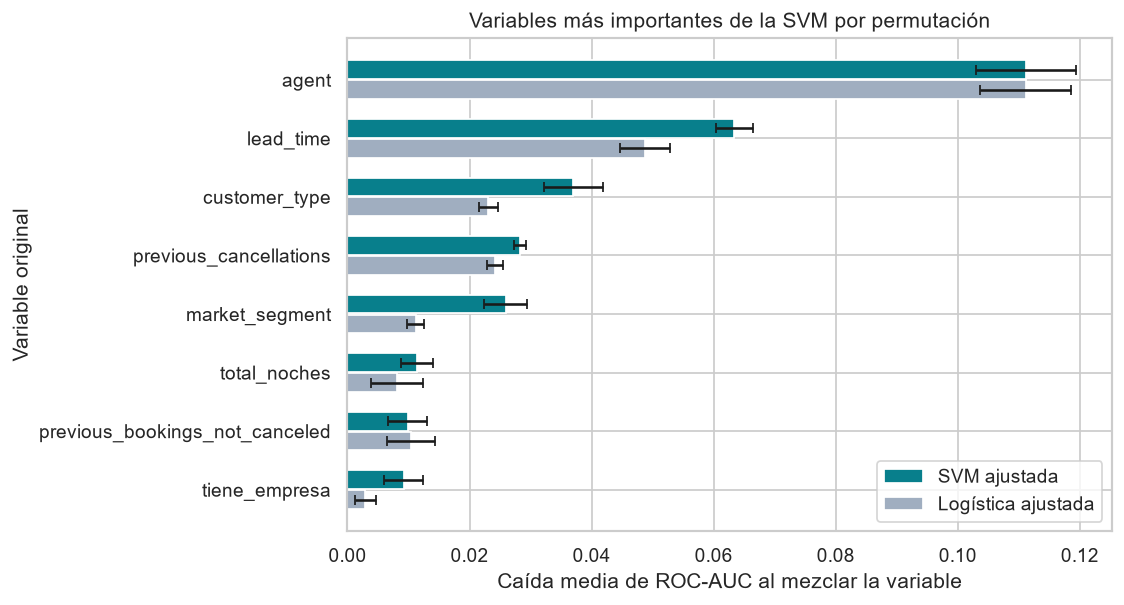

**¿Qué vemos?** En la SVM, mezclar `agent` causa la mayor caída de ROC-AUC (0.111). En la logística, la mayor caída corresponde a `agent`. El mayor coeficiente absoluto de la logística corresponde a `agent_152`. El tamaño de un coeficiente y la pérdida de capacidad para ordenar reservas miden aspectos distintos.

In [28]:
logistica_ajustada = modelos_ajustados[LOGISTICA_AJUSTADA]
coeficientes_ajustados = pd.Series(
    logistica_ajustada.named_steps["modelo"].coef_[0],
    index=logistica_ajustada.named_steps["preprocesamiento"].get_feature_names_out(),
)

filas_coeficientes = []
for variable in COLUMNAS_PREDICTORAS:
    if variable in COLUMNAS_NUMERICAS:
        candidatos = coeficientes_ajustados.loc[[f"numericas__{variable}"]]
    else:
        candidatos = coeficientes_ajustados[coeficientes_ajustados.index.str.startswith(f"categoricas__{variable}_")]
    columna = candidatos.abs().idxmax()
    filas_coeficientes.append({
        "variable": variable,
        "columna del mayor coeficiente": columna.split("__", 1)[1],
        "coeficiente logístico": candidatos[columna],
    })

ranking_svm = importancias[MODELO_FINAL].sort_values("caída ROC-AUC", ascending=False)
comparacion_importancia = (
    ranking_svm.add_prefix("SVM · ")
    .join(importancias[LOGISTICA_AJUSTADA].add_prefix("Logística · "))
    .join(pd.DataFrame(filas_coeficientes).set_index("variable"))
)
display(comparacion_importancia.round(4))

principales = ranking_svm.head(VARIABLES_GRAFICA).index[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
posiciones = np.arange(len(principales))
for nombre, desplazamiento, color in (
    (MODELO_FINAL, 0.17, COLOR_PRINCIPAL),
    (LOGISTICA_AJUSTADA, -0.17, COLOR_SECUNDARIO),
):
    datos = importancias[nombre].loc[principales]
    ax.barh(posiciones + desplazamiento, datos["caída ROC-AUC"], height=0.32,
            xerr=datos["desviación"], capsize=3, color=color, label=nombre)
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(posiciones, principales)
ax.set_title("Variables más importantes de la SVM por permutación")
ax.set_xlabel("Caída media de ROC-AUC al mezclar la variable")
ax.set_ylabel("Variable original")
ax.legend()
plt.tight_layout()
plt.show()

primera_svm = ranking_svm.index[0]
primera_logistica = importancias[LOGISTICA_AJUSTADA]["caída ROC-AUC"].idxmax()
columna_mayor_coef = coeficientes_ajustados.abs().idxmax().split("__", 1)[1]
display(Markdown(
    f"**¿Qué vemos?** En la SVM, mezclar `{primera_svm}` causa la mayor caída de ROC-AUC "
    f"({ranking_svm.loc[primera_svm, 'caída ROC-AUC']:.3f}). "
    f"En la logística, la mayor caída corresponde a `{primera_logistica}`. "
    f"El mayor coeficiente absoluto de la logística corresponde a `{columna_mayor_coef}`. "
    "El tamaño de un coeficiente y la pérdida de capacidad para ordenar reservas miden aspectos distintos."
))

La agencia y la anticipación pesan en ambos modelos. Para la SVM, mezclar el código de agencia reduce el ROC-AUC en 0,111 y mezclar la anticipación lo reduce en 0,063. En la logística, el coeficiente positivo de la anticipación indica mayor riesgo estimado a más días, manteniendo fijas las otras variables. El código de agencia también puede reflejar la mezcla de clientes y canales que gestiona cada agencia.

Las barras de error muestran cuánto cambió la caída entre las mezclas. No son intervalos de confianza. Mezclar una variable puede crear combinaciones poco comunes, y dos variables relacionadas pueden repartirse la importancia. Una caída pequeña o negativa puede reflejar la muestra o redundancia entre predictores. Estos resultados sirven para entender el modelo. Por sí solos no justifican eliminar columnas, cambiar el corte ni atribuir una causa a las cancelaciones.

La tabla y la gráfica muestran las caídas y sus desviaciones con cuatro decimales. El orden refleja esta muestra estratificada y puede variar con otra.

## 6. Estabilidad del modelo y conclusiones

### 6.1 Particiones y semilla

Partimos de los puntajes fuera de partición de la sección 4. Repetimos la validación agrupada con una semilla distinta y los mismos hiperparámetros. Cambiamos la asignación de perfiles a los folds. Cada pipeline vuelve a aprender sus escalas y categorías dentro de su fold de ajuste. Comparamos ROC-AUC y PR-AUC para evaluar el orden de riesgo sin volver a escoger cortes.

En los nuevos ajustes usamos la misma matriz numérica en formato denso para la SVM y ampliamos su caché. Esto conserva la codificación y el kernel, pero cambia cómo se guardan las entradas en memoria. Limitamos los ajustes simultáneos para contener ese costo.

In [29]:
SEMILLA_ALTERNATIVA = 17
AJUSTES_SIMULTANEOS = 3
CACHE_SVM_MB = 768
METRICAS_ESTABILIDAD = ["ROC-AUC", "PR-AUC"]


def clonar_para_estabilidad(modelo):
    """Reajusta la misma configuración con un preprocesador nuevo."""
    copia = clone(modelo)
    if isinstance(copia.named_steps["modelo"], SVC):
        copia.set_params(preprocesamiento__sparse_threshold=0, modelo__cache_size=CACHE_SVM_MB)
    return copia


def metricas_de_orden(y, puntajes):
    """Mide el orden de riesgo sin aplicar un corte."""
    return {
        "ROC-AUC": roc_auc_score(y, puntajes),
        "PR-AUC": average_precision_score(y, puntajes),
    }


particiones_alternas = list(StratifiedGroupKFold(
    n_splits=len(particiones), shuffle=True, random_state=SEMILLA_ALTERNATIVA,
).split(X_entrenamiento, y_entrenamiento, grupos_entrenamiento))
for ajuste, validacion in particiones_alternas:
    assert set(grupos_entrenamiento.iloc[ajuste]).isdisjoint(grupos_entrenamiento.iloc[validacion])

filas_estabilidad = []
for nombre, modelo in modelos_ajustados.items():
    with parallel_config(backend="threading"):
        puntajes_alternos = cross_val_predict(
            clonar_para_estabilidad(modelo), X_entrenamiento, y_entrenamiento,
            cv=particiones_alternas, method="decision_function", n_jobs=AJUSTES_SIMULTANEOS,
        )
    for numero, (_, validacion) in enumerate(particiones_alternas, start=1):
        filas_estabilidad.append({
            "modelo": nombre, "fold": numero,
            **metricas_de_orden(y_entrenamiento.iloc[validacion], puntajes_alternos[validacion]),
        })

estabilidad_alterna = pd.DataFrame(filas_estabilidad)
resumen_alterno = estabilidad_alterna.groupby("modelo")[METRICAS_ESTABILIDAD].agg(["mean", "std"])
resumen_semillas = pd.concat({
    SEMILLA: resumen_validacion[METRICAS_ESTABILIDAD],
    SEMILLA_ALTERNATIVA: pd.DataFrame({
        metrica: resumen_alterno[(metrica, "mean")].map("{:.3f}".format) + " ± "
        + resumen_alterno[(metrica, "std")].map("{:.3f}".format)
        for metrica in METRICAS_ESTABILIDAD
    }),
}, names=["semilla", "modelo"])
display(resumen_semillas)

auc_alterno = estabilidad_alterna.query("modelo == @MODELO_FINAL")["ROC-AUC"]
auc_original = resumen_validacion.loc[MODELO_FINAL, "ROC-AUC"]
display(Markdown(
    f"**¿Qué vemos?** Para la SVM, el ROC-AUC de la semilla original fue {auc_original}. "
    f"Con la semilla {SEMILLA_ALTERNATIVA} el promedio fue {auc_alterno.mean():.3f}, "
    f"con valores entre {auc_alterno.min():.3f} y {auc_alterno.max():.3f} según el fold. "
    "Esta comparación mide cuánto cambia el resultado al repartir de nuevo perfiles del mismo histórico."
))

ROC-AUC          PR-AUC
semilla modelo                                            
42      Logística ajustada   0.751 ± 0.002   0.553 ± 0.006
        SVM ajustada         0.767 ± 0.002   0.575 ± 0.006
17      Logística ajustada  0.751 ± 0.004  0.554 ± 0.006
        SVM ajustada        0.769 ± 0.004  0.576 ± 0.009

**¿Qué vemos?** Para la SVM, el ROC-AUC de la semilla original fue 0.767 ± 0.002. Con la semilla 17 el promedio fue 0.769, con valores entre 0.764 y 0.774 según el fold. Esta comparación mide cuánto cambia el resultado al repartir de nuevo perfiles del mismo histórico.

### 6.2 Validación temporal con llegadas de 2017

En entrenamiento conservamos las llegadas de 2015 y 2016 cuya salida prevista fue anterior al 1 de enero de 2017. La salida prevista aproxima el momento en que el hotel podía conocer el desenlace, porque las particiones limpias no incluyen la fecha de estado. Para evaluar usamos llegadas de 2017 con fecha estimada de registro en 2017. Retiramos del ajuste los perfiles repetidos en esa cohorte.

Usamos solo filas de la partición original de entrenamiento y reajustamos cada pipeline desde cero con las filas anteriores al corte. Dejamos fijos los hiperparámetros de la sección 4. Como esa sección los escogió con datos que incluían parte de 2017, este ejercicio es una comprobación de sensibilidad al tiempo, con una fecha de registro estimada y una aproximación de cuándo se supo el desenlace.

In [30]:
CORTE_TEMPORAL = pd.Timestamp("2017-01-01")
FIN_TEMPORAL = pd.Timestamp("2018-01-01")
CORTE_PUNTAJE_TEMPORAL = 0.0

llegadas = pd.to_datetime(entrenamiento["fecha_llegada"])
registros = pd.to_datetime(entrenamiento["fecha_registro_estimada"])
salidas_previstas = llegadas + pd.to_timedelta(entrenamiento["total_noches"], unit="D")

antes = llegadas.dt.year.isin([2015, 2016]) & salidas_previstas.lt(CORTE_TEMPORAL)
despues = llegadas.ge(CORTE_TEMPORAL) & llegadas.lt(FIN_TEMPORAL) & registros.ge(CORTE_TEMPORAL)
grupos_2017 = grupos_entrenamiento[despues]
en_ambos_periodos = antes & grupos_entrenamiento.isin(grupos_2017)
ajuste_temporal = antes & ~en_ambos_periodos

assert set(grupos_entrenamiento[ajuste_temporal]).isdisjoint(grupos_2017)
assert y_entrenamiento[ajuste_temporal].nunique() == y_entrenamiento[despues].nunique() == 2
assert registros[ajuste_temporal].max() < registros[despues].min()

print(f"Filas retiradas del ajuste por perfiles presentes en 2017: {en_ambos_periodos.sum():,}")
display(pd.DataFrame([
    {"cohorte": nombre, "filas": int(mascara.sum()), "cancelación": y_entrenamiento[mascara].mean()}
    for nombre, mascara in (("Ajuste 2015–2016", ajuste_temporal), ("Evaluación 2017", despues))
]).set_index("cohorte").round(3))

filas_temporales = []
for nombre, modelo in modelos_ajustados.items():
    ajustado = clonar_para_estabilidad(modelo).fit(X_entrenamiento[ajuste_temporal], y_entrenamiento[ajuste_temporal])
    puntajes_2017 = ajustado.decision_function(X_entrenamiento[despues])
    filas_temporales.append({
        "modelo": nombre,
        **metricas_con_corte(y_entrenamiento[despues], puntajes_2017, CORTE_PUNTAJE_TEMPORAL),
    })

resultados_temporales = pd.DataFrame(filas_temporales).set_index("modelo")
display(resultados_temporales.round(3))

auc_temporal = resultados_temporales.loc[MODELO_FINAL, "ROC-AUC"]
pr_temporal = resultados_temporales.loc[MODELO_FINAL, "PR-AUC"]
tasa_temporal = y_entrenamiento[despues].mean()
display(Markdown(
    f"**¿Qué vemos?** En 2017 la SVM obtuvo ROC-AUC de {auc_temporal:.3f} "
    f"y PR-AUC de {pr_temporal:.3f}. La tasa de cancelación en esa cohorte fue {tasa_temporal:.1%}, "
    "la referencia para interpretar PR-AUC. El F1, Recall y Precision de la tabla usan el corte "
    "cero sobre `decision_function`. Ese corte se mantuvo fijo para el diagnóstico temporal."
))

Filas retiradas del ajuste por perfiles presentes en 2017: 1,484


,filas,cancelación
cohorte,,
Ajuste 2015–2016,37856,0.268
Evaluación 2017,17390,0.289


,F1,Recall,Precision,ROC-AUC,PR-AUC,% marcadas como canceladas
modelo,,,,,,
Logística ajustada,0.548,0.758,0.430,0.727,0.482,50.937
SVM ajustada,0.555,0.730,0.447,0.729,0.483,47.188


**¿Qué vemos?** En 2017 la SVM obtuvo ROC-AUC de 0.729 y PR-AUC de 0.483. La tasa de cancelación en esa cohorte fue 28.9%, la referencia para interpretar PR-AUC. El F1, Recall y Precision de la tabla usan el corte cero sobre `decision_function`. Ese corte se mantuvo fijo para el diagnóstico temporal.

### 6.3 Qué podemos usar en el hotel

La prueba de la sección 4 deja a la SVM como la mejor de las dos alternativas evaluadas. Detectó unas tres de cada cuatro cancelaciones, con una precisión cercana a la mitad. Ese nivel sirve para priorizar confirmaciones u otras acciones de bajo costo. Una falsa alarma puede salir cara si se usa para retirar una reserva o aumentar la sobreventa.

La SVM se mantuvo cerca de 0,77 de ROC-AUC al cambiar de semilla, pero cayó a 0,729 en el ejercicio temporal. En esa cohorte obtuvo un PR-AUC de 0,483 y un F1 de 0,555 con corte cero. La cohorte, el tamaño de ajuste y el corte del F1 difieren de la prueba original, así que la caída no se puede atribuir solo al paso del tiempo. Antes de aplicar el modelo en operación haría falta probarlo en reservas nuevas, confirmar la disponibilidad de los campos al registrar y elegir el corte con los costos del hotel.